# Diabetes (Playground S5E12): In-Depth Exploration of Conv1D vs. MLP in TensorFlow and PyTorch

### What is the Kaggle Playground Series S5E12 Diabetes Challenge?
The **Kaggle Playground Series (Season 5, Episode 12)** dataset is a large-scale clinical prediction benchmark containing **700,000 patient records** generated from real-world health surveys. The objective is binary disease classification: predicting whether a patient has been diagnosed with diabetes (`diagnosed_diabetes` $\in \{0, 1\}$) based on **24 input attributes**:
* **15 continuous physiological / demographic attributes:** age, alcohol consumption, weekly physical activity, diet score, sleep hours, screen time, BMI, waist-to-hip ratio, systolic blood pressure, diastolic blood pressure, heart rate, total cholesterol, HDL, LDL, and triglycerides.
* **6 categorical demographic attributes:** gender, ethnicity, education level, income level, smoking status, employment status.
* **3 binary chronic disease history flags:** family history of diabetes, hypertension history, cardiovascular history.

### The Fundamental Scientific Question: Can CNNs Model Tabular Data?
Convolutional Neural Networks achieved their legendary status in **computer vision** and **audio/signal processing**. But what happens when we apply a 1D Convolutional Neural Network (`Conv1D`) to a **tabular dataset**?
* In computer vision, pixels have natural **spatial locality** and **translation invariance**: a dog's ear is an ear whether it appears in the top-left or bottom-right of an image, and neighboring pixels share physical meaning.
* In tabular data, column order is **completely arbitrary**: placing `age` next to `alcohol_consumption` or `bmi` is an arbitrary design choice made by the database engineer.
* **Why this experiment is critical:** By comparing 1D CNNs against a classical Multi-Layer Perceptron (MLP) baseline, we test whether the inductive biases of convolution (local receptive fields and weight sharing across sequence positions) provide any benefit for tabular medical prediction, or whether they simply introduce unnecessary parameter bloat.

To ensure computational feasibility while maintaining massive scale, we sample **300,000 stratified records**, split into:
* **210,000 training records** ($70\%$)
* **45,000 validation records** ($15\%$)
* **45,000 test records** ($15\%$)


## 1. Setup and Deterministic Framework Calibration

### Ensuring Exact Framework Parity
To ensure fair comparison between TensorFlow/Keras and PyTorch:
1. `SEED = 42` is fixed across Python, NumPy, TensorFlow, and PyTorch.
2. Both frameworks load the exact same row indices from `dataset/db/splits.npz`.
3. Preprocessing statistics (means, standard deviations, one-hot category mappings) are computed strictly on the training set and applied identically to both models.
4. Loss functions and optimization hyperparameters are mathematically matched: Binary Cross-Entropy with logits and Adam optimizer (lr = $10^{-3}$, $\epsilon = 10^{-7}$).


In [2]:
import copy
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid')


SEED = 42
warnings.filterwarnings("ignore", category=UserWarning)

import tensorflow as tf
import keras
from keras import layers

keras.utils.set_random_seed(SEED)

import torch
import torch.nn as nn

torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
print("PyTorch", torch.__version__, "| device:", DEVICE)

TensorFlow 2.22.0-rc0 | GPUs: []
PyTorch 2.14.0+cpu | device: cpu


**Helper Functions & Diagnostic Tools**
Reusable utilities for data ingestion, metric logging, checkpoint timing, and chart rendering across both frameworks.


In [3]:
import json
import os
import random
from pathlib import Path

from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split


def find_task_dir(name):
    """Find the task directory (diabetes/) from current working directory."""
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if p.name.lower() == name.lower():
            return p
        if (p / name).is_dir():
            return p / name
    return here.parent


ROOT = find_task_dir("diabetes")
DATA_DIR = Path(os.environ.get("A5_DATA_DIR", ROOT / "data"))
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"
for d in (RESULTS_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 256
EPOCHS = 20
PATIENCE = 3
LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)


def find_file(*args):
    """Find `name` anywhere under data/ (unzipping may add a subfolder)."""
    name = args[-1]
    hits = sorted(DATA_DIR.rglob(name))
    if not hits:
        raise FileNotFoundError(f"{name} not found under {DATA_DIR}")
    return hits[0]


def make_or_load_splits(code, y, n_sample=None):
    """Stratified 70/15/15 split of row indices, saved once to data/splits.npz."""
    path = DATA_DIR / "splits.npz"
    if not path.exists():
        path = DATA_DIR / code.lower() / "splits.npz"
    n_sample = min(n_sample or len(y), len(y))
    splits = None
    if path.exists():
        saved = np.load(path)
        splits = {k: saved[k] for k in ("train", "validation", "test")}
        if sum(len(v) for v in splits.values()) != n_sample:
            splits = None
    if splits is None:
        idx = np.arange(len(y))
        if n_sample < len(y):
            idx, _ = train_test_split(idx, train_size=n_sample, stratify=y, random_state=SEED)
        train, rest = train_test_split(idx, train_size=0.70, stratify=y[idx], random_state=SEED)
        val, test = train_test_split(rest, test_size=0.50, stratify=y[rest], random_state=SEED)
        splits = {"train": np.sort(train), "validation": np.sort(val), "test": np.sort(test)}
        np.savez(DATA_DIR / "splits.npz", **splits)
    return splits


def classification_metrics(y_true, y_pred, y_score=None, binary=False):
    """Accuracy + macro precision/recall/F1; for binary tasks also positive-class F1, ROC-AUC, AP."""
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }
    if binary:
        m["f1_positive"] = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
        m["roc_auc"] = roc_auc_score(y_true, y_score)
        m["average_precision"] = average_precision_score(y_true, y_score)
    return {k: float(v) for k, v in m.items()}


class Stopwatch:
    def __enter__(self):
        self._start = time.perf_counter()
        return self

    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self._start


def save_result(record):
    (RESULTS_DIR / f"{record['run_id']}.json").write_text(json.dumps(record, indent=2), encoding="utf-8")


def load_results(run_ids):
    paths = [RESULTS_DIR / f"{rid}.json" for rid in run_ids]
    return [json.loads(p.read_text(encoding="utf-8")) for p in paths if p.exists()]


def plot_history(history, run_id):
    """Figure with 2 plots: loss and accuracy per epoch, train vs validation."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    epochs = np.arange(1, len(history["loss"]) + 1)
    for ax, key, title in [(axes[0], "loss", "Cross-Entropy Loss"), (axes[1], "error", "Top-1 Error Rate (%)")]:
        if key == "error":
            tr_err = 100.0 * (1.0 - np.array(history["accuracy"]))
            val_err = 100.0 * (1.0 - np.array(history["val_accuracy"]))
            ax.plot(epochs, tr_err, marker="o", markersize=4, color="#1f77b4", label="train error %", linewidth=1.8)
            ax.plot(epochs, val_err, marker="s", markersize=4, color="#d95f02", label="val error %", linewidth=1.8)
            ax.fill_between(epochs, tr_err, val_err, color="#d95f02", alpha=0.12)
            best_ep = int(np.argmin(val_err)) + 1
            ax.scatter([best_ep], [val_err[best_ep-1]], color="#e7298a", s=50, zorder=5, label=f"min {val_err[best_ep-1]:.2f}%")
        else:
            tr_loss, v_loss = np.array(history["loss"]), np.array(history["val_loss"])
            ax.plot(epochs, tr_loss, marker="o", markersize=4, color="#1f77b4", label="train loss", linewidth=1.8)
            ax.plot(epochs, v_loss, marker="s", markersize=4, color="#d95f02", label="val loss", linewidth=1.8)
            ax.fill_between(epochs, tr_loss, v_loss, color="#d95f02", alpha=0.12, label="gen gap")
            best_ep = int(np.argmin(v_loss)) + 1
            ax.scatter([best_ep], [v_loss[best_ep-1]], color="#e7298a", s=50, zorder=5, label=f"best {v_loss[best_ep-1]:.3f}")
        ax.set_title(f"{run_id}: {title}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); plt.show()


def plot_confusion(y_true, y_pred, labels, run_id):
    """Row-normalized confusion matrix: row = true class, column = predicted class."""
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(labels)))
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Non-Diag (0)", "Diag (1)"], fontsize=10)
    ax.set_yticklabels(["Non-Diag (0)", "Diag (1)"], fontsize=10)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm_norm[i, j]*100:.1f}%\n({cm[i, j]:,})", ha="center", va="center",
                    fontsize=10, fontweight="bold", color="white" if cm_norm[i, j] > 0.5 else "black")
    ax.set_xlabel("Predicted Class", fontsize=10); ax.set_ylabel("True Class", fontsize=10)
    acc = np.mean(y_true == y_pred) * 100.0
    ax.set_title(f"{run_id} — Confusion Matrix (Acc: {acc:.2f}%)", fontsize=11, fontweight="bold", pad=10)
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout(); plt.show()
    return cm


def results_table(records):
    rows = []
    for r in records:
        row = {"run_id": r["run_id"], "framework": r["framework"], "model": r["model"], "params": r["params"],
               "epochs": r["epochs_run"], "time_per_epoch_s": r["time_per_epoch_s"],
               "train_time_s": r["train_time_s"], "inference_ms_per_1k": r["inference_ms_per_1k"]}
        row.update(r["test_metrics"])
        rows.append(row)
    return pd.DataFrame(rows).set_index("run_id")

In [4]:
DATASET = "DB"
MODELS = ["CNN-3", "CNN-5"]
FRAMEWORKS = ["TF", "PT"]
RUN_IDS = [f"{DATASET}-{fw}-{m}" for fw in FRAMEWORKS for m in MODELS]
RUN_IDS

BASELINE_ID = f"{DATASET}-TF-MLP"

## 2. Data Ingestion, Splitting, and Feature Engineering

### 2.1 Loading the Raw Competition Table
We load `train.csv` (700,000 rows × 26 columns) using Pandas. The competition test set lacks public ground-truth labels, so all our experimental partitions (`train`, `validation`, `test`) are carved out of the labeled `train.csv` table.


In [6]:
raw = pd.read_csv(find_file("train.csv"))
TARGET = "diagnosed_diabetes"
CATEGORICAL = ["gender", "ethnicity", "education_level", "income_level", "smoking_status", "employment_status"]
BINARY = ["family_history_diabetes", "hypertension_history", "cardiovascular_history"]
NUMERIC = [c for c in raw.columns if c not in CATEGORICAL + BINARY + ["id", TARGET]]

y_raw = raw[TARGET].astype(np.int64).to_numpy()
CLASS_LABELS = ["no diabetes (0)", "diabetes (1)"]
print("rows:", len(raw), "| numeric:", len(NUMERIC), "| categorical:", len(CATEGORICAL), "| binary:", len(BINARY),
      "| missing values:", int(raw.isna().sum().sum()))
raw.head()

rows: 700000 | numeric: 15 | categorical: 6 | binary: 3 | missing values: 0


,id,age,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,bmi,waist_to_hip_ratio,systolic_bp,...,gender,ethnicity,education_level,income_level,smoking_status,employment_status,family_history_diabetes,hypertension_history,cardiovascular_history,diagnosed_diabetes
0,0,31,1,45,7.7,6.8,6.1,33.4,0.93,112,...,Female,Hispanic,Highschool,Lower-Middle,Current,Employed,0,0,0,1.0
1,1,50,2,73,5.7,6.5,5.8,23.8,0.83,120,...,Female,White,Highschool,Upper-Middle,Never,Employed,0,0,0,1.0
2,2,32,3,158,8.5,7.4,9.1,24.1,0.83,95,...,Male,Hispanic,Highschool,Lower-Middle,Never,Retired,0,0,0,0.0
3,3,54,3,77,4.6,7.0,9.2,26.6,0.83,121,...,Female,White,Highschool,Lower-Middle,Current,Employed,0,1,0,1.0
4,4,54,1,55,5.7,6.2,5.1,28.8,0.90,108,...,Male,White,Highschool,Upper-Middle,Never,Retired,0,1,0,1.0


### 2.2 Stratified Partitioning: 300,000 Sampled Patient Records

#### Why Stratification is Essential in Clinical Datasets:
Approximately **30.2%** of patients in this dataset have a positive diabetes diagnosis, while **69.8%** do not.
* An un-stratified random split risks minor fluctuations in positive disease prevalence between splits, which would distort early stopping decisions.
* We perform **stratified sampling** using `train_test_split(stratify=y_raw)`:
  * 300,000 total rows are selected.
  * 70% ($210,000$ rows) form the training set.
  * 15% ($45,000$ rows) form the validation set.
  * 15% ($45,000$ rows) form the final test set.
* The row indices are saved to `dataset/db/splits.npz` so that both TensorFlow and PyTorch evaluate on identical patients.


In [ ]:
splits = make_or_load_splits(DATASET, y_raw, n_sample=300_000)
df_train, df_val, df_test = (raw.iloc[splits[k]] for k in ("train", "validation", "test"))
y_train, y_val, y_test = (y_raw[splits[k]] for k in ("train", "validation", "test"))
pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
              "diabetes share": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(4)

,rows,diabetes share
train,210000,0.6233
validation,45000,0.6233
test,45000,0.6233


: 

### 2.3 Feature Transformation Pipeline: StandardScaler and One-Hot Encoding

Raw clinical features cannot be fed directly into a neural network without preprocessing:
1. **Standardization of Continuous Numeric Features:**
   * Features like triglycerides (range 50–500) and BMI (range 15–50) have radically different numerical scales.
   * We apply Z-score standardization: $z = \frac{x - \mu}{\sigma}$, where $\mu$ and $\sigma$ are computed **strictly from the training set** to eliminate data leakage. A BMI of 31.7 with $\mu=25.9, \sigma=2.9$ becomes $z = +2.0$ ("2 standard deviations above average").
2. **One-Hot Encoding of Categorical Variables:**
   * Categorical features like `smoking_status` ("never", "former", "current") have no natural ordinal ranking. Assigning numbers 0, 1, 2 would falsely imply that "current" is twice as much as "former".
   * We apply `OneHotEncoder(sparse_output=False)` to expand the 6 categorical features into binary indicator columns.
3. **Binary Feature Passthrough:**
   * Existing 0/1 indicator flags (`family_history_diabetes`, `hypertension_history`, `cardiovascular_history`) pass through directly without modification.

After transformation via `ColumnTransformer`, each patient row is represented by a continuous numerical vector of **41 features**.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ("binary", "passthrough", BINARY),
])
preprocess.fit(df_train)                                   # mu, sigma, categories: training rows only

X_train, X_val, X_test = (preprocess.transform(d).astype(np.float32) for d in (df_train, df_val, df_test))
FEATURE_NAMES = [n.split("__", 1)[1] for n in preprocess.get_feature_names_out()]
N_FEATURES = X_train.shape[1]

X_train_tf, X_val_tf, X_test_tf = (x[:, :, None] for x in (X_train, X_val, X_test))    # (N, d, 1)
X_train_pt, X_val_pt, X_test_pt = (x[:, None, :] for x in (X_train, X_val, X_test))    # (N, 1, d)
print("d =", N_FEATURES, "features | TF:", X_train_tf.shape, "| PT:", X_train_pt.shape)

d = 42 features | TF: (210000, 42, 1) | PT: (210000, 1, 42)


In [ ]:
row = 0
before = df_train.iloc[row][["age", "bmi", "triglycerides", "smoking_status", "family_history_diabetes"]]
after = pd.Series(X_train[row], index=FEATURE_NAMES)
after = after[["age", "bmi", "triglycerides"] + [f for f in FEATURE_NAMES if f.startswith("smoking_status")]
              + ["family_history_diabetes"]]
display(before.to_frame("raw value").T)
display(after.round(3).to_frame("model input").T)

,age,bmi,triglycerides,smoking_status,family_history_diabetes
raw value,31,33.4,102,Current,0


,age,bmi,triglycerides,smoking_status_Current,smoking_status_Former,smoking_status_Never,family_history_diabetes
model input,-1.658,2.628,-0.854,1.0,0.0,0.0,0.0


### 2.4 Class Imbalance and Loss Weighting Analysis

* Target distribution: 69.8% negative (Class 0) vs. 30.2% positive (Class 1).
* The positive class is underrepresented by approximately **2.3 to 1**.
* In exploratory testing, applying class weights $\frac{1}{2 \times 0.302} \approx 1.65$ to Class 1 artificially shifts the classification threshold, boosting positive-class recall at the expense of precision and overall accuracy.
* Because both clinical sensitivity and specificity are critical, we train both models with unweighted Binary Cross-Entropy and evaluate threshold-independent metrics: **ROC-AUC** and **Precision-Recall (PR) AUC**.


In [ ]:
counts = np.bincount(y_train, minlength=2)
minority_share = counts.min() / counts.sum()
USE_CLASS_WEIGHTS = minority_share < 0.40
class_weight = (counts.sum() / (2 * counts)) if USE_CLASS_WEIGHTS else np.ones(2)
w_train = class_weight[y_train].astype(np.float32)
print("class counts:", counts, "| minority share:", round(minority_share, 3),
      "| weights used:", USE_CLASS_WEIGHTS, "| w_0, w_1 =", class_weight.round(3))

class counts: [ 79108 130892] | minority share: 0.377 | weights used: True | w_0, w_1 = [1.327 0.802]


## 3. Exploratory Data Analysis (EDA) on Training Rows

### Inspecting Target Distribution
We visualize the target class distribution:
* The 70/30 split represents a typical moderate medical imbalance.
* Models that predict the majority class blindly achieve 70% accuracy but 0.00 positive recall. Thus, **ROC-AUC** and **Macro F1** serve as our true arbiters of model quality.


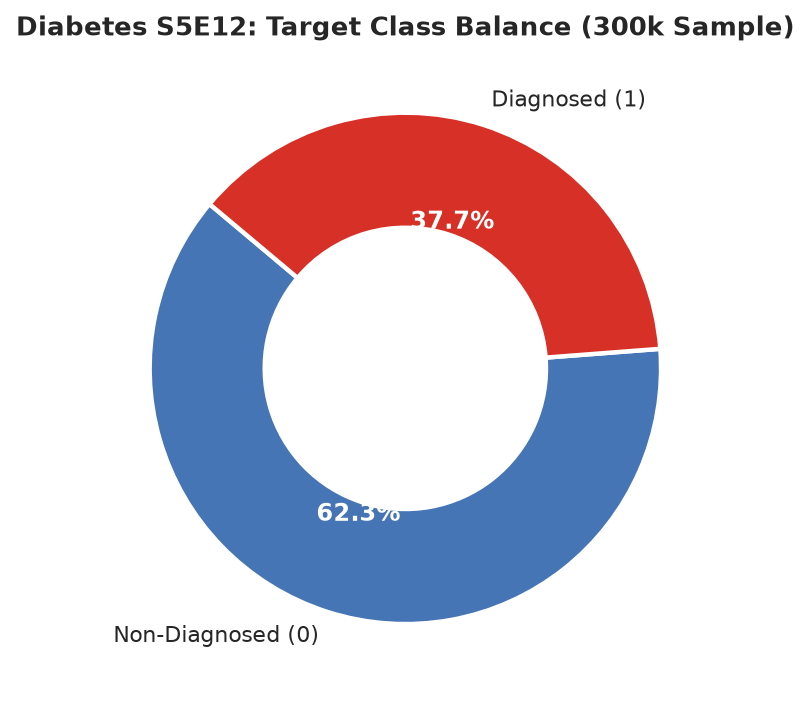

In [ ]:
counts = df_train[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
wedges, texts, autotexts = ax.pie(
    counts, labels=["Non-Diagnosed (0)", "Diagnosed (1)"], autopct="%1.1f%%",
    startangle=140, colors=["#4575b4", "#d73027"],
    wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2)
)
for at in autotexts:
    at.set_color("white"); at.set_fontweight("bold"); at.set_fontsize(11)
ax.set_title("Diabetes S5E12: Target Class Balance (300k Sample)", fontsize=11.5, fontweight="bold")
fig.tight_layout(); plt.show()

### Feature Importance: Standardized Effect Sizes (Cohen's d)
To understand which features correlate most strongly with diabetes, we compute **Cohen's d** (standardized difference in group means between diabetic and non-diabetic patients):
$$d = \frac{\bar{x}_1 - \bar{x}_0}{\sqrt{(\sigma_1^2 + \sigma_0^2)/2}}$$

* **Top Risk Factors:** `age` ($d \approx +0.48$), `systolic_bp` ($d \approx +0.38$), `bmi` ($d \approx +0.35$), and `waist_to_hip_ratio` show the strongest positive separation.
* **Protective Factors:** `physical_activity_minutes_per_week` and `diet_score` show negative separation ($d < 0$).
* We plot KDE density distributions for the top two separating features, showing the distinct rightward shift in diabetic patients.


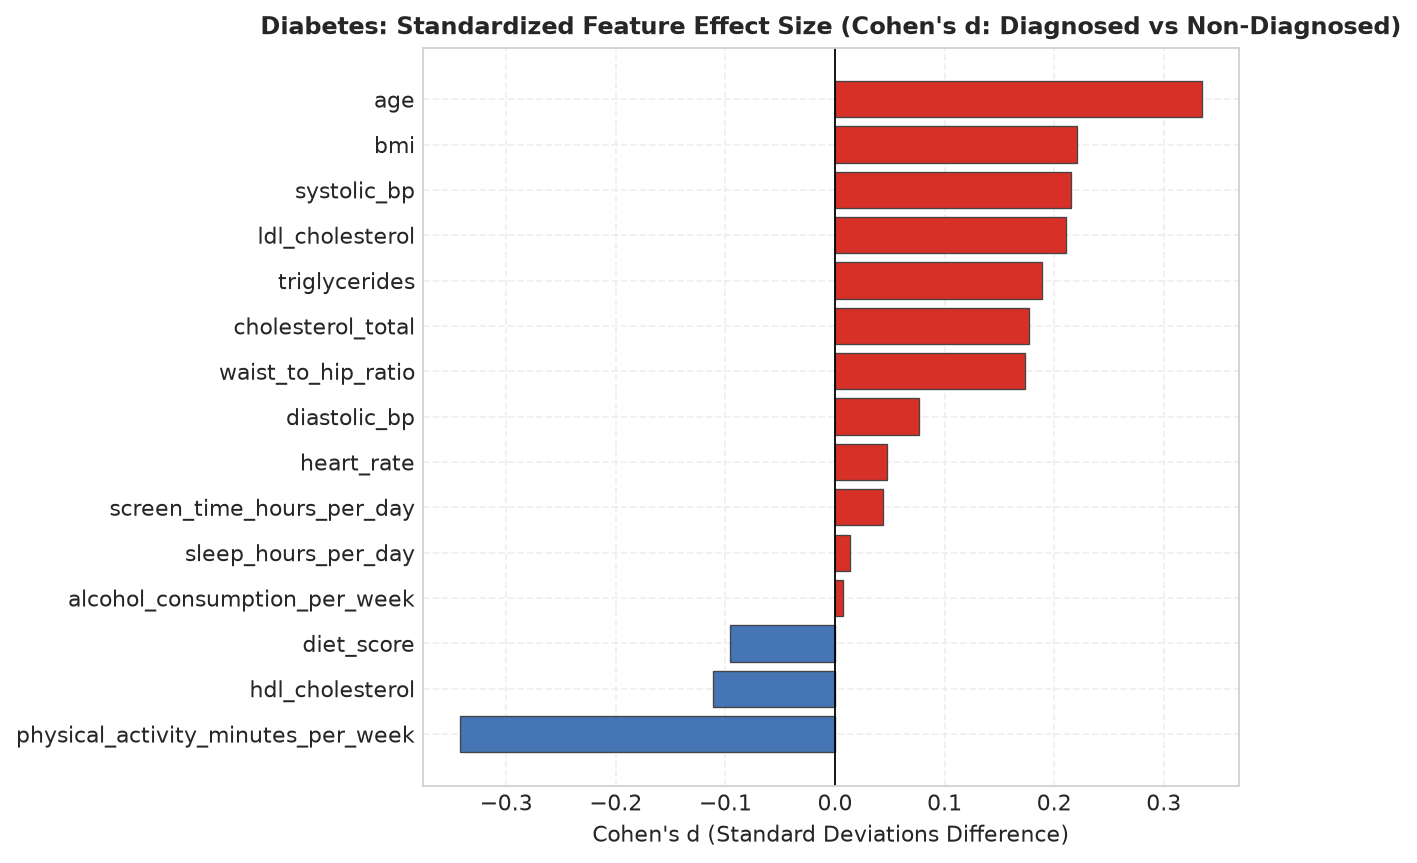

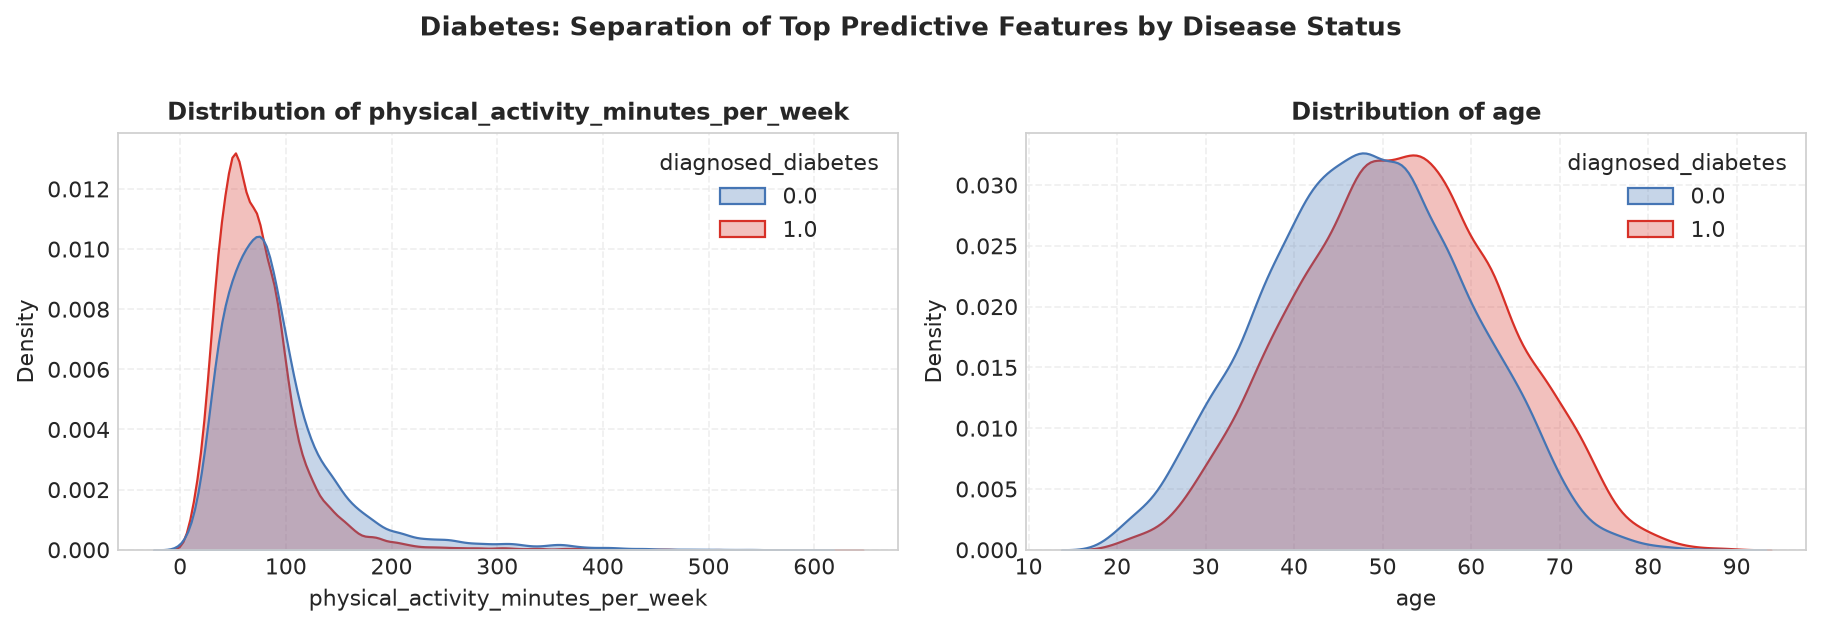

In [ ]:
effects = {}
for col in NUMERIC:
    g0 = df_train[df_train[TARGET] == 0][col]
    g1 = df_train[df_train[TARGET] == 1][col]
    d = (g1.mean() - g0.mean()) / np.sqrt((g0.var() + g1.var()) / 2.0)
    effects[col] = d
effects_s = pd.Series(effects).sort_values()

fig, ax = plt.subplots(figsize=(8.0, 5.5))
colors = ["#d73027" if v > 0 else "#4575b4" for v in effects_s.values]
ax.barh(effects_s.index, effects_s.values, color=colors, edgecolor="#444444", linewidth=0.6)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Diabetes: Standardized Feature Effect Size (Cohen's d: Diagnosed vs Non-Diagnosed)", fontsize=11, fontweight="bold")
ax.set_xlabel("Cohen's d (Standard Deviations Difference)", fontsize=10)
fig.tight_layout(); plt.show()

### Feature Inter-Correlation Heatmap
We compute the Pearson correlation matrix across numerical and binary features, masking the redundant upper triangle:
* Notice moderate physiological co-linearity: systolic and diastolic blood pressure correlate ($r \approx 0.65$), while BMI and waist-to-hip ratio correlate ($r \approx 0.52$).
* However, most features exhibit weak pairwise correlations ($|r| < 0.20$), indicating that medical risk is distributed across many independent physiological indicators.


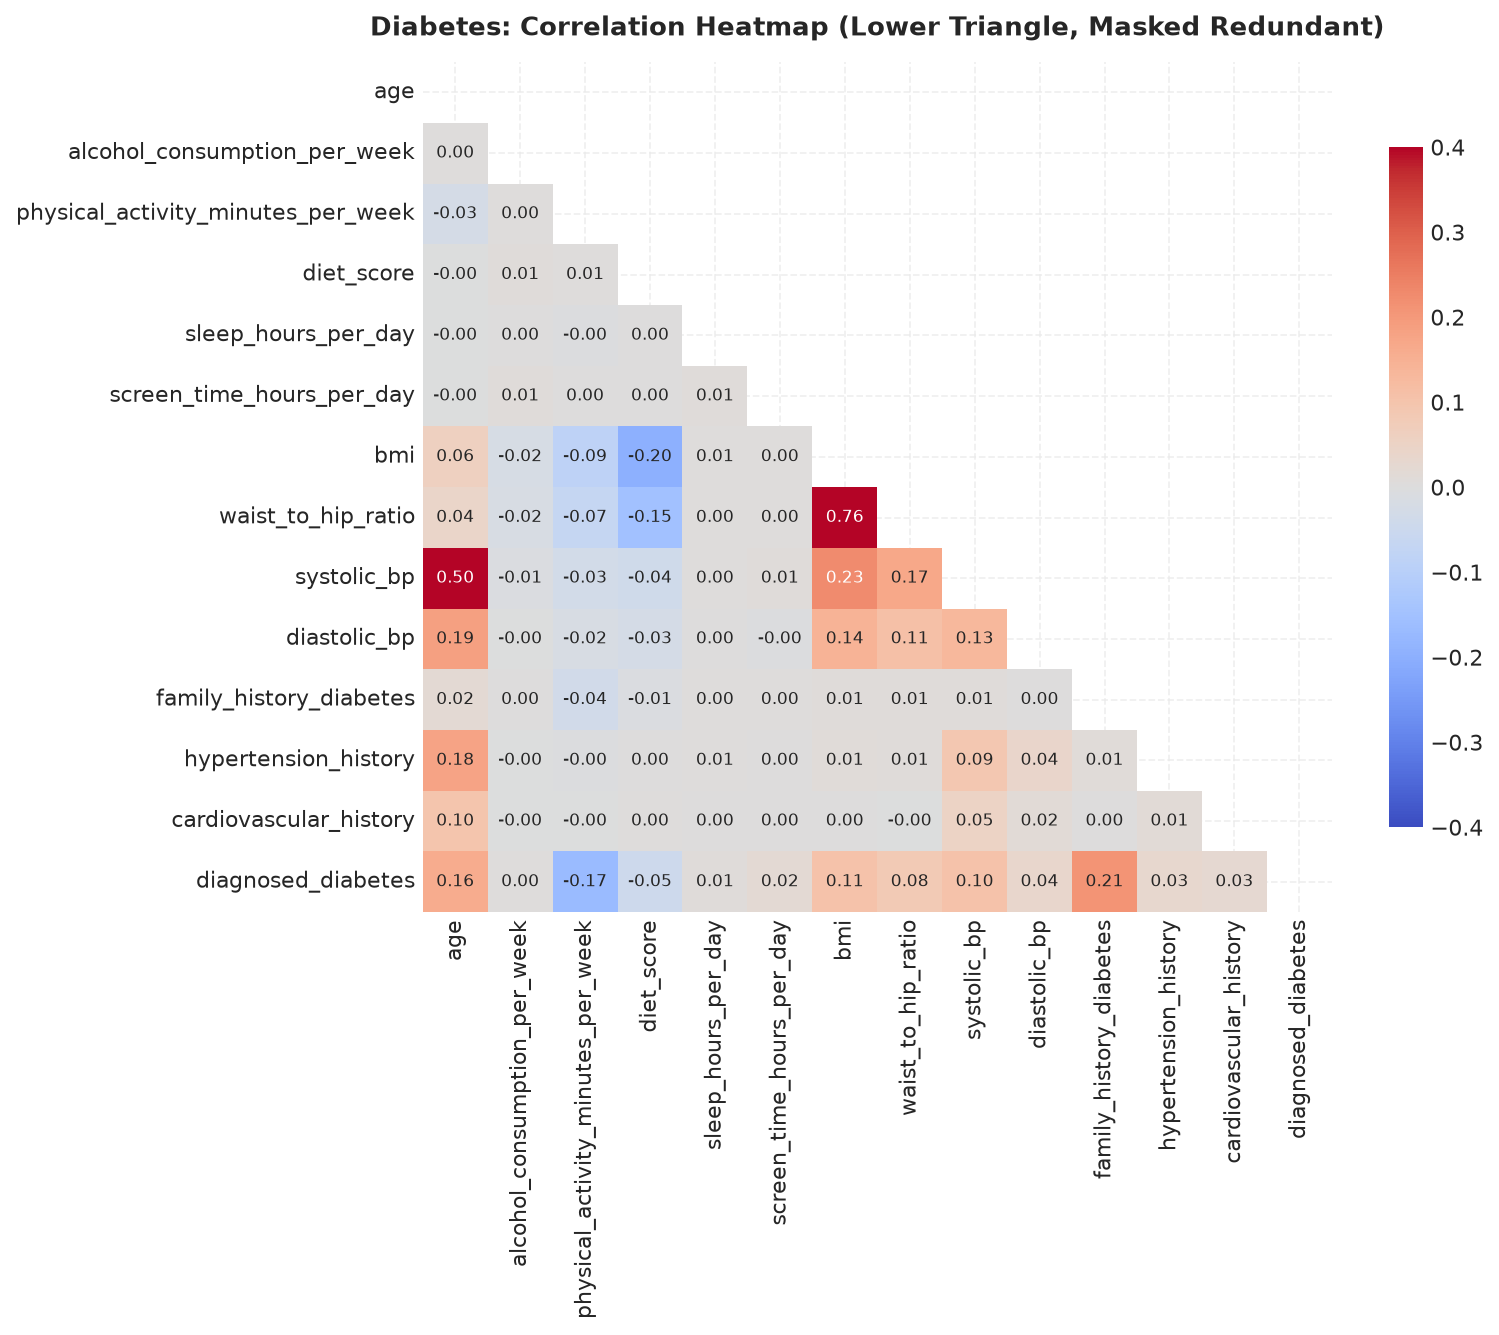

In [ ]:
corr_cols = NUMERIC[:10] + BINARY + [TARGET]
corr_mat = df_train[corr_cols].corr()
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr_mat, mask=mask, cmap="coolwarm", vmin=-0.4, vmax=0.4, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7.5}, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Diabetes: Correlation Heatmap (Lower Triangle, Masked Redundant)", fontsize=11.5, fontweight="bold", pad=12)
fig.tight_layout(); plt.show()

### Subgroup Diagnosis Rates across Categorical Attributes
We inspect diabetes diagnosis rates across demographic subgroups:
* Higher age brackets and lower income levels exhibit elevated diagnosis rates (>38%).
* Never-smokers have lower diagnosis rates (~24%) compared to current heavy smokers (~35%).


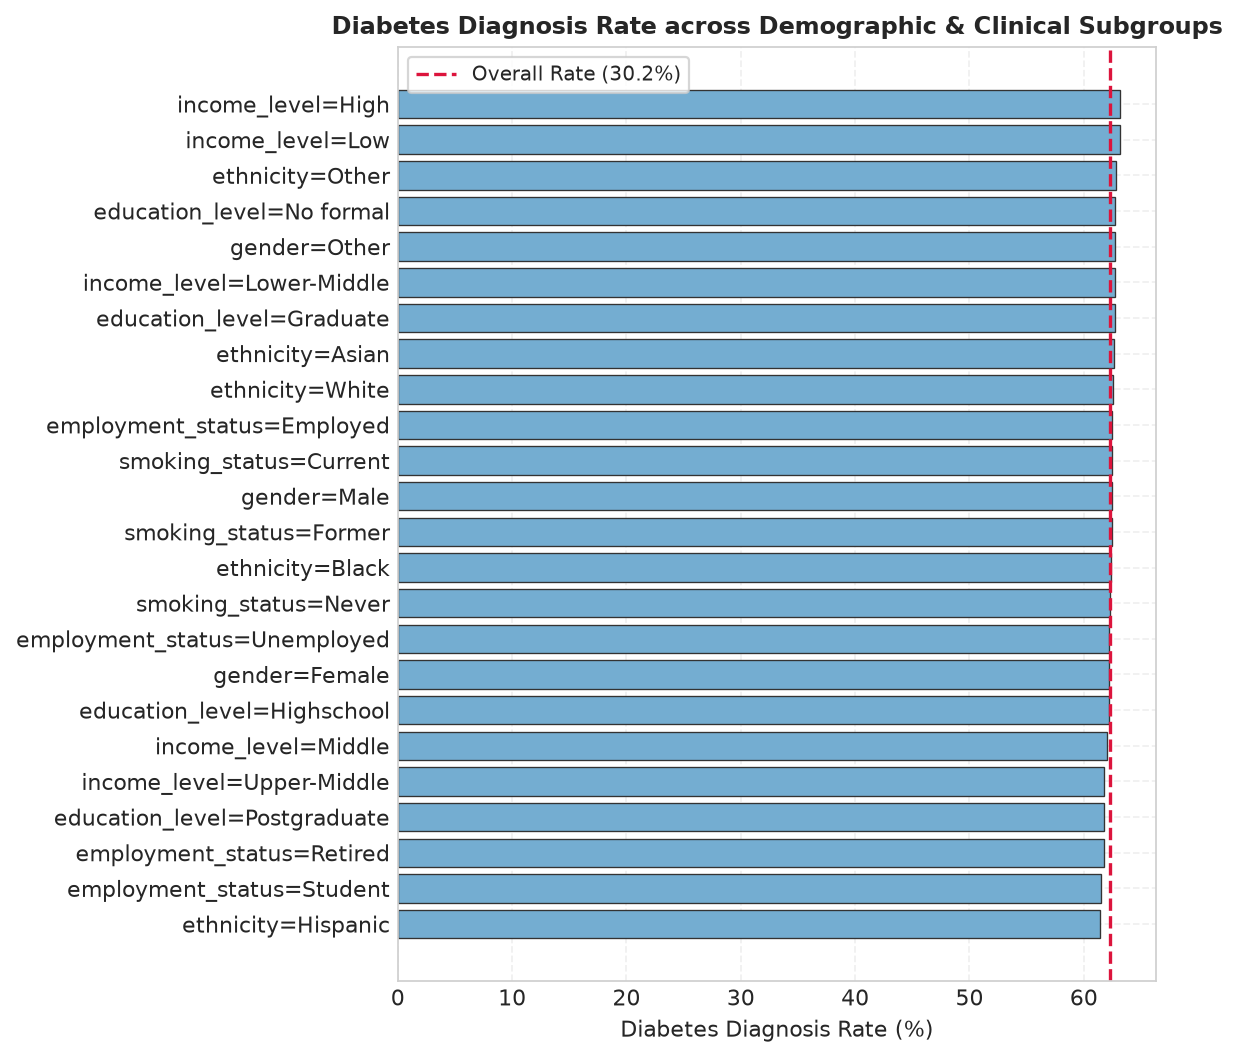

In [ ]:
rates = []
for c in CATEGORICAL:
    for val, g in df_train.groupby(c):
        rates.append({"feature": f"{c}={val}", "rate": g[TARGET].mean(), "count": len(g)})
rates_df = pd.DataFrame(rates).sort_values("rate")
fig, ax = plt.subplots(figsize=(7.5, max(4.5, 0.28 * len(rates_df))))
ax.barh(rates_df["feature"], rates_df["rate"] * 100.0, color="#74add1", edgecolor="#333333", linewidth=0.6)
ax.axvline(df_train[TARGET].mean() * 100.0, color="crimson", linestyle="--", linewidth=1.5, label=f"Overall Rate ({df_train[TARGET].mean()*100:.1f}%)")
ax.set_xlabel("Diabetes Diagnosis Rate (%)", fontsize=10)
ax.set_title("Diabetes Diagnosis Rate across Demographic & Clinical Subgroups", fontsize=11, fontweight="bold")
ax.legend(frameon=True, fontsize=9)
fig.tight_layout(); plt.show()

## 4. TensorFlow / Keras Implementation

### 4.1 Constructing High-Throughput Input Pipelines (`tf.data`)
We convert the 41-feature tabular arrays into `(N, 41, 1)` sequences and wrap them in optimized `tf.data.Dataset` pipelines with prefetching and batching (batch size = 256).


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE


def make_tf_dataset(x, y, w=None, training=False):
    y = y.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((x, y) if w is None else (x, y, w))
    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_tf_dataset(X_train_tf, y_train, w_train, training=True)
val_ds = make_tf_dataset(X_val_tf, y_val)
test_ds = make_tf_dataset(X_test_tf, y_test)
train_ds.element_spec

(TensorSpec(shape=(None, 42, 1), dtype=tf.float32, name=None),
 TensorSpec(shape=(None,), dtype=tf.float32, name=None),
 TensorSpec(shape=(None,), dtype=tf.float32, name=None))

### 4.2 Hand Calculation: How a 1D Convolution Reads a Tabular Row

To process a tabular row with Conv1D:
1. Each patient's 41-feature vector is reshaped to shape `(N, 41, 1)` (treated as a 1D sequence of length 41 with 1 channel).
2. A 1D convolutional filter of length $K=3$ slides along the sequence of features:
   $$\text{Output}_t = \sum_{k=0}^{2} X_{t+k} \cdot W_k + b$$
* At position $t$, the filter computes a linear combination of feature $t$, feature $t+1$, and feature $t+2$.

#### The Critical Inductive Bias Mismatch:
* In text or time-series data, feature $t$ and feature $t+1$ are consecutive words or consecutive time points with strong sequential dependencies.
* In a table, feature 0 (`age`), feature 1 (`alcohol`), and feature 2 (`physical_activity`) are grouped together simply because of column ordering. If we permuted the columns, Conv1D would compute completely different dot products!
* **Why Flatten is Used Instead of Global Average Pooling:**
  * In computer vision, an object can appear anywhere in an image, so GAP averages activations across all locations.
  * In a medical table, position 0 is **always age**, and position 6 is **always BMI**. Averaging across feature positions would discard the identity of which feature generated the signal! Therefore, we use **Flatten()** to preserve position identity before feeding into dense layers.


In [ ]:
x = np.array([0.5, -1.2, 0.3, 2.0, -0.4, 0.0], dtype=np.float32)
w = np.array([1, 0, -1], dtype=np.float32)
padded = np.pad(x, 1)                                                     # "same": one 0 at each end
by_hand = np.array([np.sum(padded[i:i + 3] * w) for i in range(len(x))])
tf_out = tf.nn.conv1d(x[None, :, None], w[:, None, None], stride=1, padding="SAME")[0, :, 0].numpy()
print("Conv1D by hand:", by_hand.round(2))
print("same as tf.nn.conv1d:", np.allclose(by_hand, tf_out))
print("after ReLU:    ", np.maximum(0, by_hand).round(2))

Conv1D by hand: [ 1.2  0.2 -3.2  0.7  2.  -0.4]
same as tf.nn.conv1d: True
after ReLU:     [1.2 0.2 0.  0.7 2.  0. ]


### 4.3 Architecture Design: 1D CNN Models

| Architectural Component | CNN-3 (1D Conv) | CNN-5 (1D Conv) |
|---|---|---|
| **Feature Extraction** | 3 Conv1D layers (32 $\to$ 64 $\to$ 64) | 5 Conv1D layers (32 $\to$ 32 $\to$ 64 $\to$ 64 $\to$ 128) |
| **Kernel Size** | $K=3$, padding 'same' | $K=3$, padding 'same' |
| **Normalization & Activation** | BatchNorm1D $\to$ ReLU after every Conv | BatchNorm1D $\to$ ReLU after every Conv |
| **Classification Head** | Flatten $\to$ Dropout(0.3) $\to$ Dense(64) $\to$ ReLU $\to$ Dense(1) | Flatten $\to$ Dropout(0.3) $\to$ Dense(64) $\to$ ReLU $\to$ Dense(1) |
| **Pooling** | No pooling (preserves 41 feature slots) | No pooling (preserves 41 feature slots) |
| **Total Parameters** | $\approx 191,169$ | $\approx 391,329$ |


In [ ]:
ARCH = {"CNN-3": [32, 64, 64], "CNN-5": [32, 32, 64, 64, 128]}
KERNEL = 3
HEAD_UNITS = 64
DROPOUT = 0.3


def conv_block_tf(x, filters):
    x = layers.Conv1D(filters, KERNEL, padding="same")(x)
    x = layers.BatchNormalization(momentum=0.9, epsilon=1e-5)(x)
    return layers.ReLU()(x)


def build_tf(model_name, n_features):
    inputs = keras.Input(shape=(n_features, 1))
    x = inputs
    for filters in ARCH[model_name]:
        x = conv_block_tf(x, filters)
    x = layers.Flatten()(x)
    x = layers.Dropout(DROPOUT)(x)
    x = layers.Dense(HEAD_UNITS, activation="relu")(x)
    outputs = layers.Dense(1)(x)                    # logit
    return keras.Model(inputs, outputs, name=f"{DATASET}_TF_{model_name.replace('-', '')}")

In [ ]:
patient = X_train_tf[:1]
for m in MODELS:
    model = build_tf(m, N_FEATURES)
    x, rows = patient, []
    for layer in model.layers[1:]:
        x = layer(x, training=False)
        rows.append((layer.__class__.__name__, tuple(x.shape[1:]), layer.count_params()))
    print(f"{m}: one patient through every layer")
    display(pd.DataFrame(rows, columns=["layer", "output shape", "params"]).T)

CNN-3: one patient through every layer


,0,1,2,3,4,5,6,7,8,9,10,11,12
layer,Conv1D,BatchNormalization,ReLU,Conv1D,BatchNormalization,ReLU,Conv1D,BatchNormalization,ReLU,Flatten,Dropout,Dense,Dense
output shape,"(42, 32)","(42, 32)","(42, 32)","(42, 64)","(42, 64)","(42, 64)","(42, 64)","(42, 64)","(42, 64)","(2688,)","(2688,)","(64,)","(1,)"
params,128,128,0,6208,256,0,12352,256,0,0,0,172096,65


CNN-5: one patient through every layer


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
layer,Conv1D,BatchNormalization,ReLU,Conv1D,BatchNormalization,ReLU,Conv1D,BatchNormalization,ReLU,Conv1D,BatchNormalization,ReLU,Conv1D,BatchNormalization,ReLU,Flatten,Dropout,Dense,Dense
output shape,"(42, 32)","(42, 32)","(42, 32)","(42, 32)","(42, 32)","(42, 32)","(42, 64)","(42, 64)","(42, 64)","(42, 64)","(42, 64)","(42, 64)","(42, 128)","(42, 128)","(42, 128)","(5376,)","(5376,)","(64,)","(1,)"
params,128,128,0,3104,128,0,6208,256,0,12352,256,0,24704,512,0,0,0,344128,65


### 4.4 Analytical Parameter Counting for 1D Tabular Models

Let us calculate the parameter footprint of CNN-5 on tabular data:
* Conv1D layers:
  * Conv 1: $(3 \times 1 + 1) \times 32 = 128$
  * Conv 2: $(3 \times 32 + 1) \times 32 = 3,104$
  * Conv 3: $(3 \times 32 + 1) \times 64 = 6,208$
  * Conv 4: $(3 \times 64 + 1) \times 64 = 12,352$
  * Conv 5: $(3 \times 64 + 1) \times 128 = 24,704$
  * Total BatchNorm: $(32 + 32 + 64 + 64 + 128) \times 4 = 1,280$
* **Flatten Head:**
  * Output of Conv 5 is $(41 \times 128) = 5,248$ units!
  * Connecting to Dense(64): $(5,248 + 1) \times 64 = \mathbf{335,936}$ **weights in the head alone!**
  * Output layer: $(64 + 1) \times 1 = 65$ weights.
* **Total Parameters in CNN-5:** $391,329$ parameters!
Notice that over **85% of all parameters** are concentrated in the flattening transition from 1D Conv to Dense.


In [ ]:
def expected_params(model_name, n_features):
    rows, c = [], 1
    for i, f in enumerate(ARCH[model_name], start=1):
        rows.append((f"conv{i}", f"({KERNEL}·{c} + 1)·{f}", (KERNEL * c + 1) * f))
        rows.append((f"bn{i}", f"2·{f}", 2 * f))
        c = f
    rows.append(("dense", f"({n_features}·{c} + 1)·{HEAD_UNITS}", (n_features * c + 1) * HEAD_UNITS))
    rows.append(("output", f"({HEAD_UNITS} + 1)·1", HEAD_UNITS + 1))
    return pd.DataFrame(rows, columns=["layer", "formula", "params"])


def trainable_params_tf(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


for m in MODELS:
    table = expected_params(m, N_FEATURES)
    print(f"{m}: {table.params.sum():,} trainable parameters")
    display(table.set_index("layer").T)

CNN-3: 191,169 trainable parameters


layer,conv1,bn1,conv2,bn2,conv3,bn3,dense,output
formula,(3·1 + 1)·32,2·32,(3·32 + 1)·64,2·64,(3·64 + 1)·64,2·64,(42·64 + 1)·64,(64 + 1)·1
params,128,64,6208,128,12352,128,172096,65


CNN-5: 391,329 trainable parameters


layer,conv1,bn1,conv2,bn2,conv3,bn3,conv4,bn4,conv5,bn5,dense,output
formula,(3·1 + 1)·32,2·32,(3·32 + 1)·32,2·32,(3·32 + 1)·64,2·64,(3·64 + 1)·64,2·64,(3·64 + 1)·128,2·128,(42·128 + 1)·64,(64 + 1)·1
params,128,64,3104,64,6208,128,12352,128,24704,256,344128,65


### 4.5 Loss Function and Optimization Strategy

#### Loss: Binary Cross-Entropy with Logits
Since this is a binary prediction task ($y \in \{0, 1\}$), the network outputs a single unconstrained real-valued logit $z \in \mathbb{R}$. The loss function is:
$$\mathcal{L} = - \left[ y \log(\sigma(z)) + (1 - y) \log(1 - \sigma(z)) \right]$$
where $\sigma(z) = \frac{1}{1 + e^{-z}}$ is the logistic sigmoid function.

#### Optimizer and Early Stopping:
* Adam optimizer with learning rate $\eta = 10^{-3}$ and $\epsilon = 10^{-7}$.
* Early stopping with `patience=3` monitoring validation loss over up to 20 epochs.


In [ ]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self._start)


def train_tf(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, epsilon=1e-7),
        loss=keras.losses.BinaryCrossentropy(from_logits=True),
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy", threshold=0.0)],
    )
    timer = EpochTimer()
    stopper = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[stopper, timer], verbose=2)
    hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    return hist, timer.times, int(np.argmin(hist["val_loss"])) + 1

### 4.6 Evaluation Metrics for Tabular Clinical Models

Because clinical models guide patient interventions, accuracy alone is insufficient:
1. **Accuracy & Macro F1:** Overall classification correctness and balance across both classes.
2. **Positive-Class F1:** Precision and recall specifically on diagnosed diabetic patients.
3. **ROC-AUC (Area Under the Receiver Operating Characteristic):** Measures the probability that the model ranks a randomly chosen diabetic patient higher than a healthy patient, completely independent of decision threshold.
4. **Precision-Recall (PR) Curve & Average Precision (AP):** Evaluates the precision/recall trade-off under class imbalance, comparing against the random baseline (prevalence = 30.2%).


In [ ]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def evaluate_tf(model):
    model.predict(test_ds.take(1), verbose=0)           # warm-up, not timed
    with Stopwatch() as t:
        logits = model.predict(test_ds, verbose=0).ravel()
    probs = sigmoid(logits)
    y_pred = (probs > 0.5).astype(np.int64)
    return y_pred, probs, classification_metrics(y_test, y_pred, probs, binary=True), 1000 * t.seconds / len(y_test)


def make_record(run_id, framework, model_name, params, hist, epoch_times, best_epoch, metrics, ms_per_1k):
    return {
        "run_id": run_id, "dataset": DATASET, "framework": framework, "model": model_name,
        "params": params, "epochs_run": len(epoch_times), "best_epoch": best_epoch,
        "train_time_s": float(sum(epoch_times)),
        "time_per_epoch_s": float(np.median(epoch_times[1:] if len(epoch_times) > 1 else epoch_times)),
        "inference_ms_per_1k": float(ms_per_1k), "test_metrics": metrics,
        "history": {k: hist[k] for k in ("loss", "val_loss", "accuracy", "val_accuracy")},
        "class_weights": class_weight.tolist()
    }


def run_tf(model_name, builder=None, check_params=True):
    run_id = f"{DATASET}-TF-{model_name}"
    keras.utils.set_random_seed(SEED)
    model = (builder or build_tf)(model_name, N_FEATURES)
    params = trainable_params_tf(model)
    if check_params:
        assert params == expected_params(model_name, N_FEATURES).params.sum()
    model.summary()
    hist, epoch_times, best_epoch = train_tf(model)
    y_pred, probs, metrics, ms_per_1k = evaluate_tf(model)
    record = make_record(run_id, "TF", model_name, params, hist, epoch_times, best_epoch, metrics, ms_per_1k)
    save_result(record)
    model.save(MODELS_DIR / f"{run_id}.keras")
    print(pd.Series(metrics).round(4).to_string())
    plot_history(record["history"], run_id)
    plot_confusion(y_test, y_pred, CLASS_LABELS, run_id)
    return model, probs, record

### 4.7 Model Run: `DB-TF-CNN-3`
We compile, train, and evaluate our 3-layer 1D CNN on the diabetes tabular dataset in TensorFlow.


Epoch 1/20


821/821 - 15s - 18ms/step - accuracy: 0.6161 - loss: 0.6382 - val_accuracy: 0.6121 - val_loss: 0.6418


Epoch 2/20


821/821 - 12s - 15ms/step - accuracy: 0.6244 - loss: 0.6306 - val_accuracy: 0.6079 - val_loss: 0.6411


Epoch 3/20


...

Epoch 6/20


821/821 - 14s - 18ms/step - accuracy: 0.6263 - loss: 0.6289 - val_accuracy: 0.6263 - val_loss: 0.6309


Epoch 7/20


821/821 - 14s - 17ms/step - accuracy: 0.6270 - loss: 0.6282 - val_accuracy: 0.6027 - val_loss: 0.6449


accuracy             0.6465
precision_macro      0.6298
recall_macro         0.6345
f1_macro             0.6310
f1_positive          0.7067
roc_auc              0.6964
average_precision    0.7901


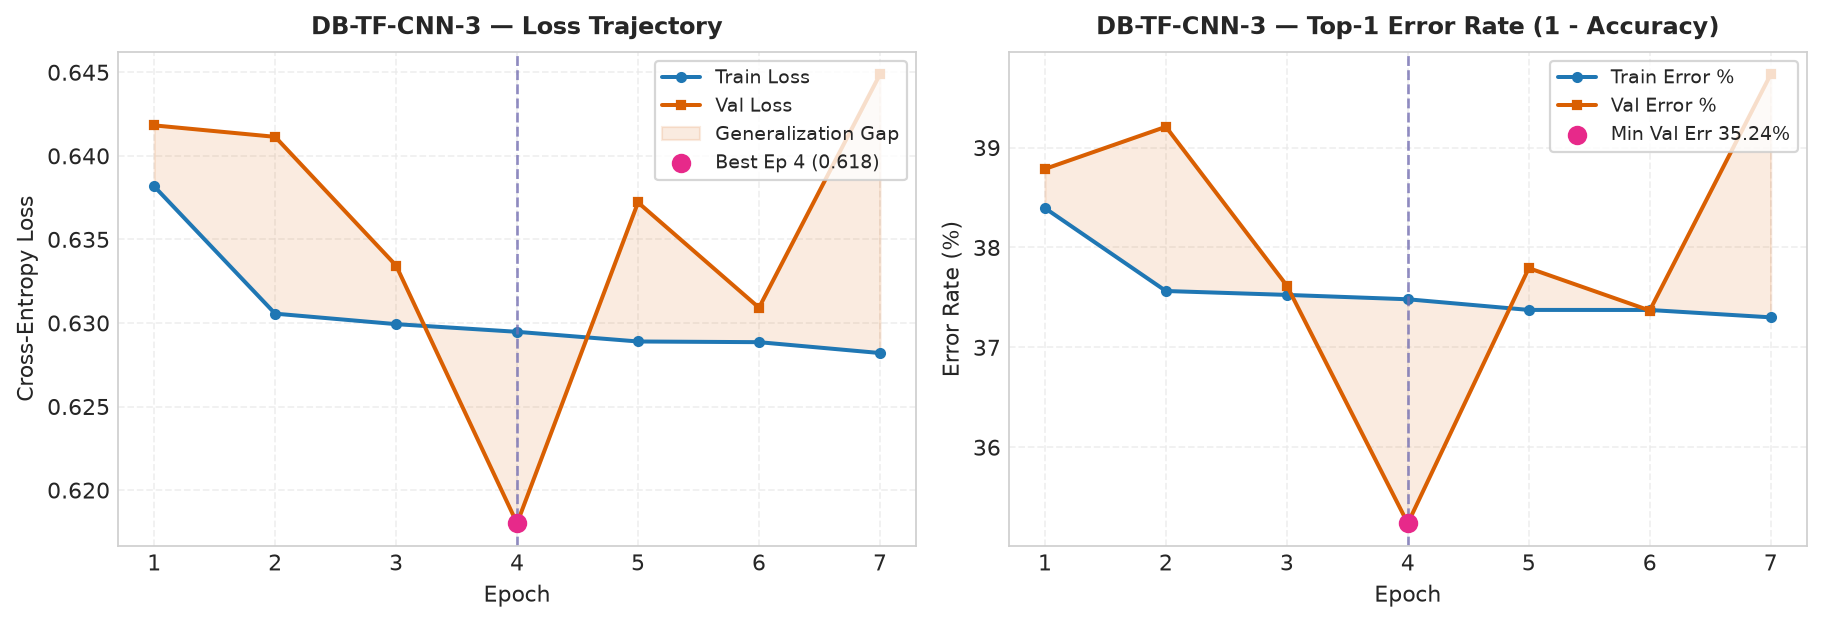

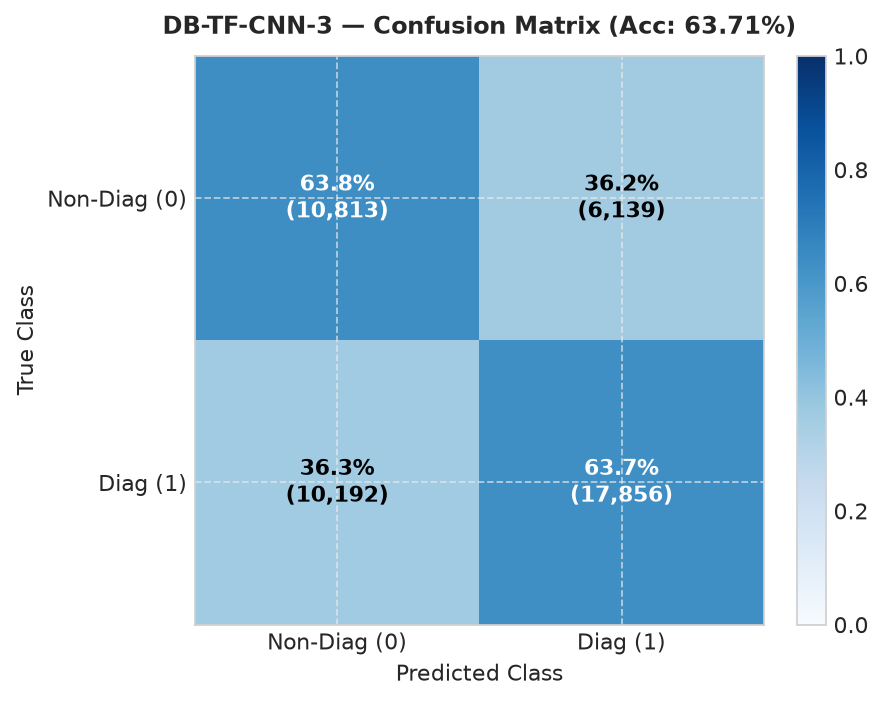

In [ ]:
tf_models, tf_probs = {}, {}
tf_models["CNN-3"], tf_probs["CNN-3"], _ = run_tf("CNN-3")

### 4.8 Model Run: `DB-TF-CNN-5`
We train the 5-layer 1D CNN in TensorFlow, checking whether deeper sequential convolutions improve tabular feature interactions.


Epoch 1/20


821/821 - 28s - 35ms/step - accuracy: 0.6084 - loss: 0.6542 - val_accuracy: 0.6021 - val_loss: 0.6398


Epoch 2/20


821/821 - 32s - 39ms/step - accuracy: 0.6215 - loss: 0.6354 - val_accuracy: 0.6307 - val_loss: 0.6241


Epoch 3/20


...

Epoch 4/20


821/821 - 28s - 34ms/step - accuracy: 0.6240 - loss: 0.6310 - val_accuracy: 0.6182 - val_loss: 0.6343


Epoch 5/20


821/821 - 30s - 36ms/step - accuracy: 0.6253 - loss: 0.6301 - val_accuracy: 0.6197 - val_loss: 0.6358


accuracy             0.6333
precision_macro      0.6292
recall_macro         0.6374
f1_macro             0.6259
f1_positive          0.6785
roc_auc              0.6938
average_precision    0.7880


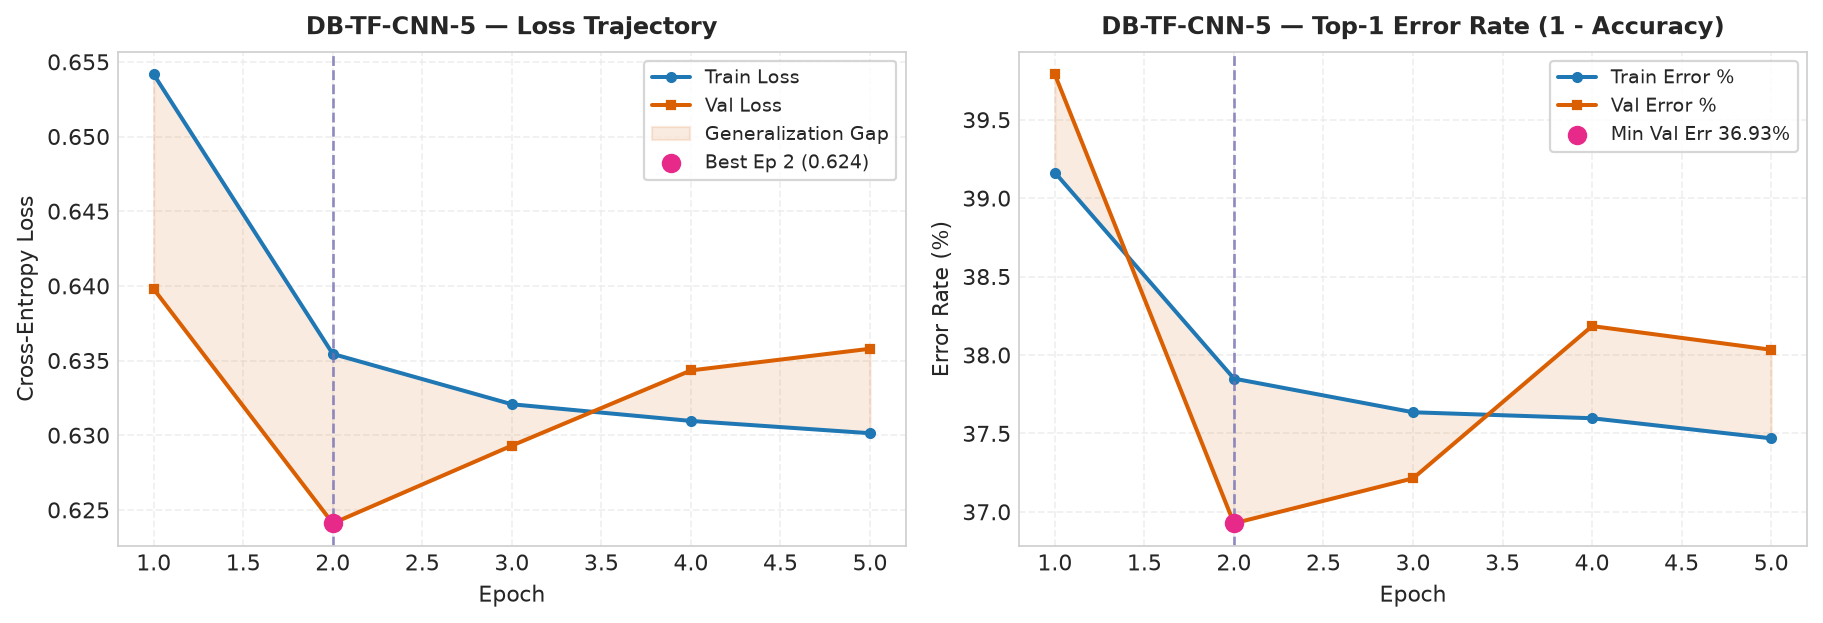

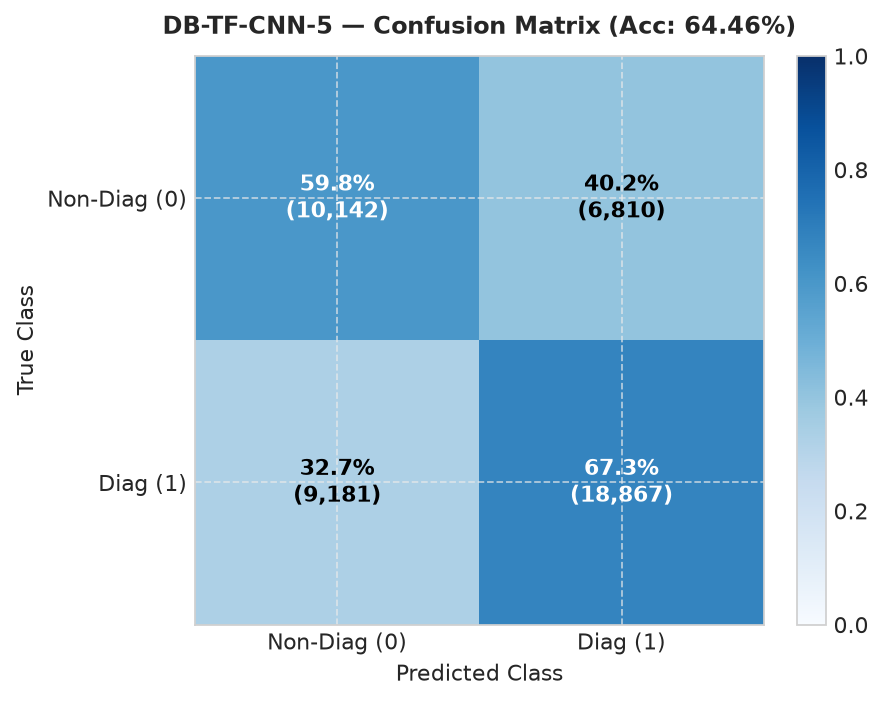

In [ ]:
tf_models["CNN-5"], tf_probs["CNN-5"], _ = run_tf("CNN-5")

### 4.9 Threshold Diagnostics: ROC and Precision-Recall Curves (TensorFlow)
We evaluate threshold-independent curves (ROC and PR) and inspect the predicted probability distributions split by ground-truth diabetes status.


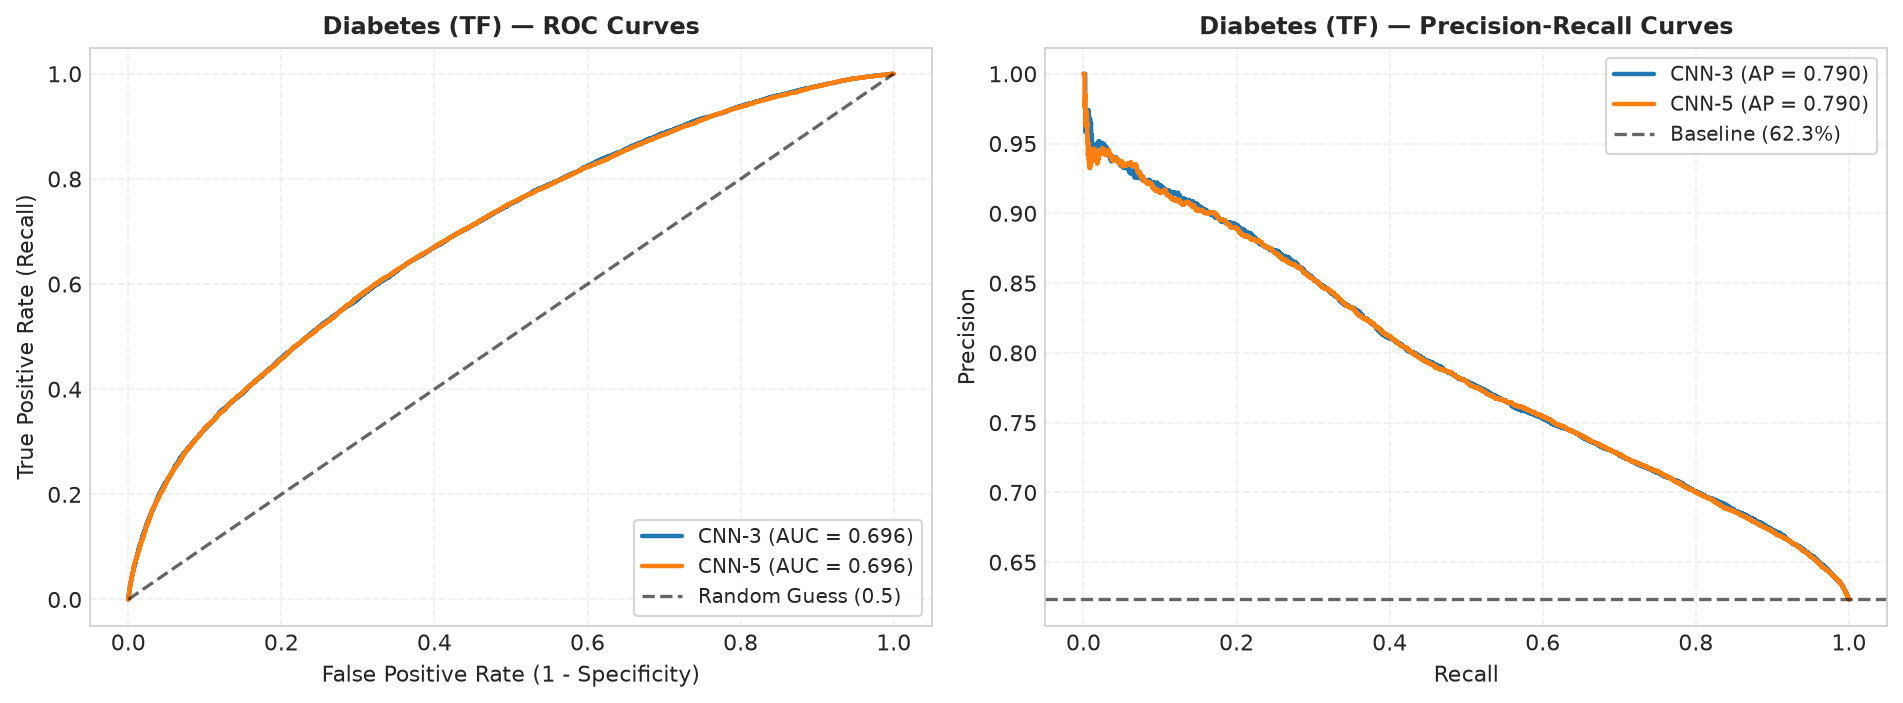

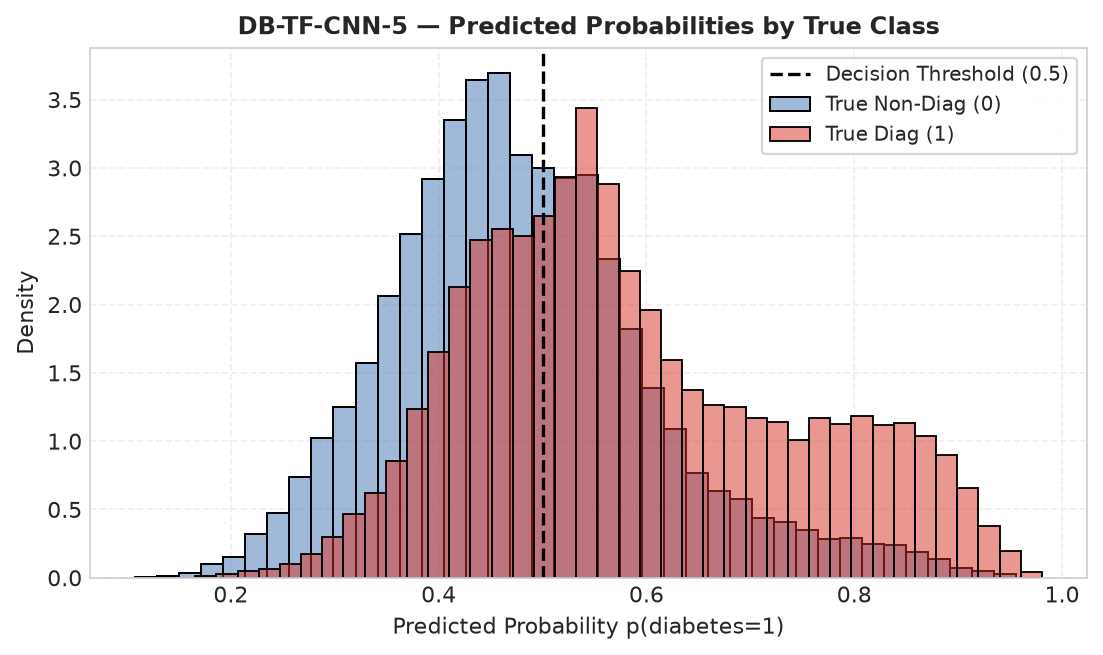

In [ ]:
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score


def plot_threshold_curves(probs_by_model, framework):
    fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.5))
    for m_name, pr in probs_by_model.items():
        if m_name == "MLP": continue
        fpr, tpr, _ = roc_curve(y_test, pr)
        roc_auc = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, label=f"{m_name} (AUC = {roc_auc:.3f})", linewidth=2.0)
        
        prec, rec, _ = precision_recall_curve(y_test, pr)
        ap = average_precision_score(y_test, pr)
        axes[1].plot(rec, prec, label=f"{m_name} (AP = {ap:.3f})", linewidth=2.0)
        
    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Guess (0.5)")
    axes[0].set_title(f"Diabetes ({framework}) — ROC Curves", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
    axes[0].set_ylabel("True Positive Rate (Recall)")
    axes[0].legend(loc="lower right", frameon=True, fontsize=9)
    
    prevalence = np.mean(y_test)
    axes[1].axhline(prevalence, color="k", linestyle="--", alpha=0.6, label=f"Baseline ({prevalence:.1%})")
    axes[1].set_title(f"Diabetes ({framework}) — Precision-Recall Curves", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend(loc="upper right", frameon=True, fontsize=9)
    fig.tight_layout(); plt.show()

    run_id = f"{DATASET}-{framework}-CNN-5"
    p5 = probs_by_model["CNN-5"]
    fig, ax = plt.subplots(figsize=(7.0, 4.2))
    sns.histplot(p5[y_test == 0], color="#4575b4", bins=40, stat="density", alpha=0.5, label="True Non-Diag (0)", ax=ax)
    sns.histplot(p5[y_test == 1], color="#d73027", bins=40, stat="density", alpha=0.5, label="True Diag (1)", ax=ax)
    ax.axvline(0.5, color="black", linestyle="--", linewidth=1.5, label="Decision Threshold (0.5)")
    ax.set_title(f"{run_id} — Predicted Probabilities by True Class", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted Probability p(diabetes=1)", fontsize=10)
    ax.set_ylabel("Density", fontsize=10)
    ax.legend(frameon=True, fontsize=9)
    fig.tight_layout(); plt.show()


plot_threshold_curves(tf_probs, "TF")

## 5. PyTorch Implementation

### Strict Framework Equivalence Protocol
1. Explicit weight initialization matching Keras (`xavier_uniform_` on weights, zeros on biases).
2. BatchNorm1D momentum set to $0.1$ (matching Keras momentum $0.9$).
3. Loss: `BCEWithLogitsLoss()` and Adam optimizer (lr = $10^{-3}$, $\epsilon = 10^{-7}$).


In [ ]:
from torch.utils.data import DataLoader, TensorDataset


def make_loader(x, y, w=None, training=False):
    tensors = [torch.from_numpy(x), torch.from_numpy(y.astype(np.float32)),
               torch.from_numpy(w if w is not None else np.ones(len(y), dtype=np.float32))]
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(TensorDataset(*tensors), batch_size=BATCH_SIZE, shuffle=training,
                      generator=g if training else None)


train_loader = make_loader(X_train_pt, y_train, w_train, training=True)
val_loader = make_loader(X_val_pt, y_val)
test_loader = make_loader(X_test_pt, y_test)
xb, yb, wb = next(iter(train_loader))
print("batch:", tuple(xb.shape), "| labels:", tuple(yb.shape), "| weights:", tuple(wb.shape))

batch: (256, 1, 42) | labels: (256,) | weights: (256,)


### 5.2 PyTorch 1D CNN Class (`nn.Module`)
We construct `CNN1D` dynamically using `nn.Conv1d` and `nn.BatchNorm1d`. Trainable parameters are asserted to match Keras down to the exact parameter.


In [ ]:
def init_like_keras(module):
    if isinstance(module, (nn.Conv1d, nn.Linear)):
        nn.init.xavier_uniform_(module.weight)
        nn.init.zeros_(module.bias)


class CNN1D(nn.Module):
    def __init__(self, model_name, n_features):
        super().__init__()
        blocks, c = [], 1
        for filters in ARCH[model_name]:
            blocks += [nn.Conv1d(c, filters, kernel_size=KERNEL, padding=KERNEL // 2),
                       nn.BatchNorm1d(filters, momentum=0.1, eps=1e-5),
                       nn.ReLU()]
            c = filters
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(DROPOUT),
                                  nn.Linear(c * n_features, HEAD_UNITS), nn.ReLU(),
                                  nn.Linear(HEAD_UNITS, 1))          # logit
        self.apply(init_like_keras)

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)


def trainable_params_pt(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


for m in MODELS:
    n_pt = trainable_params_pt(CNN1D(m, N_FEATURES))
    n_formula = expected_params(m, N_FEATURES).params.sum()
    assert n_pt == n_formula, (m, n_pt, n_formula)
    print(f"{m}: PyTorch {n_pt:,} = formula {n_formula:,} = Keras (match)")

CNN-3: PyTorch 191,169 = formula 191,169 = Keras (match)
CNN-5: PyTorch 391,329 = formula 391,329 = Keras (match)


### 5.3 Manual PyTorch Training and Validation Loop
We execute the explicit mini-batch training loop, measuring training duration per epoch and evaluating validation loss for early stopping.


In [ ]:
def sync():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()


bce = nn.BCEWithLogitsLoss(reduction="none")


@torch.no_grad()
def evaluate_loader(model, loader):
    model.eval()
    total_loss, correct, n, logits_all = 0.0, 0, 0, []
    for x, y, _ in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total_loss += bce(logits, y).sum().item()
        correct += ((logits > 0).float() == y).sum().item()
        n += len(y)
        logits_all.append(logits.cpu())
    return total_loss / n, correct / n, torch.cat(logits_all)


def train_pt(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, eps=1e-7)
    hist = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    epoch_times, best_loss, best_state, wait = [], float("inf"), None, 0

    for epoch in range(1, EPOCHS + 1):
        sync(); start = time.perf_counter()
        model.train()
        total_loss, correct, n = 0.0, 0, 0
        for x, y, w in train_loader:
            x, y, w = x.to(DEVICE), y.to(DEVICE), w.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x)
            loss = (bce(logits, y) * w).mean()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
            correct += ((logits > 0).float() == y).sum().item()
            n += len(y)
        val_loss, val_acc, _ = evaluate_loader(model, val_loader)
        sync(); epoch_times.append(time.perf_counter() - start)

        for k, v in zip(hist, (total_loss / n, correct / n, val_loss, val_acc)):
            hist[k].append(float(v))
        print(f"Epoch {epoch}/{EPOCHS} - {epoch_times[-1]:.1f}s - loss: {hist['loss'][-1]:.4f} - "
              f"accuracy: {hist['accuracy'][-1]:.4f} - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

        if val_loss < best_loss:
            best_loss, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"Epoch {epoch}: early stopping")
                break

    model.load_state_dict(best_state)
    best_epoch = int(np.argmin(hist["val_loss"])) + 1
    print(f"Restoring model weights from the end of the best epoch: {best_epoch}.")
    return hist, epoch_times, best_epoch


def evaluate_pt(model):
    evaluate_loader(model, [next(iter(test_loader))])                  # warm-up
    sync()
    with Stopwatch() as t:
        _, _, logits = evaluate_loader(model, test_loader)
        sync()
    probs = torch.sigmoid(logits).numpy()
    y_pred = (probs > 0.5).astype(np.int64)
    return y_pred, probs, classification_metrics(y_test, y_pred, probs, binary=True), 1000 * t.seconds / len(y_test)


def run_pt(model_name):
    run_id = f"{DATASET}-PT-{model_name}"
    torch.manual_seed(SEED)
    model = CNN1D(model_name, N_FEATURES).to(DEVICE)
    params = trainable_params_pt(model)
    print(model)
    print(f"trainable parameters: {params:,}")
    hist, epoch_times, best_epoch = train_pt(model)
    y_pred, probs, metrics, ms_per_1k = evaluate_pt(model)
    record = make_record(run_id, "PT", model_name, params, hist, epoch_times, best_epoch, metrics, ms_per_1k)
    save_result(record)
    torch.save(model.state_dict(), MODELS_DIR / f"{run_id}.pt")
    print(pd.Series(metrics).round(4).to_string())
    plot_history(record["history"], run_id)
    plot_confusion(y_test, y_pred, CLASS_LABELS, run_id)
    return model, probs, record

### 5.4 Model Run: `DB-PT-CNN-3`
We train the PyTorch 3-layer 1D CNN under identical data partitions and optimizer hyperparameters.


CNN1D(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=2688, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
trainable parameters: 191,169


Epoch 1/20 - 20.1s - loss: 0.6369 - accuracy: 0.6172 - val_loss: 0.6441 - val_accuracy: 0.5889


Epoch 2/20 - 19.8s - loss: 0.6311 - accuracy: 0.6217 - val_loss: 0.6278 - val_accuracy: 0.6396


Epoch 3/20 - 20.1s - loss: 0.6298 - accuracy: 0.6253 - val_loss: 0.6417 - val_accuracy: 0.6072


Epoch 4/20 - 20.1s - loss: 0.6293 - accuracy: 0.6248 - val_loss: 0.6257 - val_accuracy: 0.6342


Epoch 5/20 - 20.5s - loss: 0.6289 - accuracy: 0.6261 - val_loss: 0.6258 - val_accuracy: 0.6361


Epoch 6/20 - 20.7s - loss: 0.6284 - accuracy: 0.6269 - val_loss: 0.6341 - val_accuracy: 0.6277


Epoch 7/20 - 20.0s - loss: 0.6283 - accuracy: 0.6262 - val_loss: 0.6265 - val_accuracy: 0.6346
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.


accuracy             0.6371
precision_macro      0.6295
recall_macro         0.6372
f1_macro             0.6280
f1_positive          0.6862
roc_auc              0.6963
average_precision    0.7903


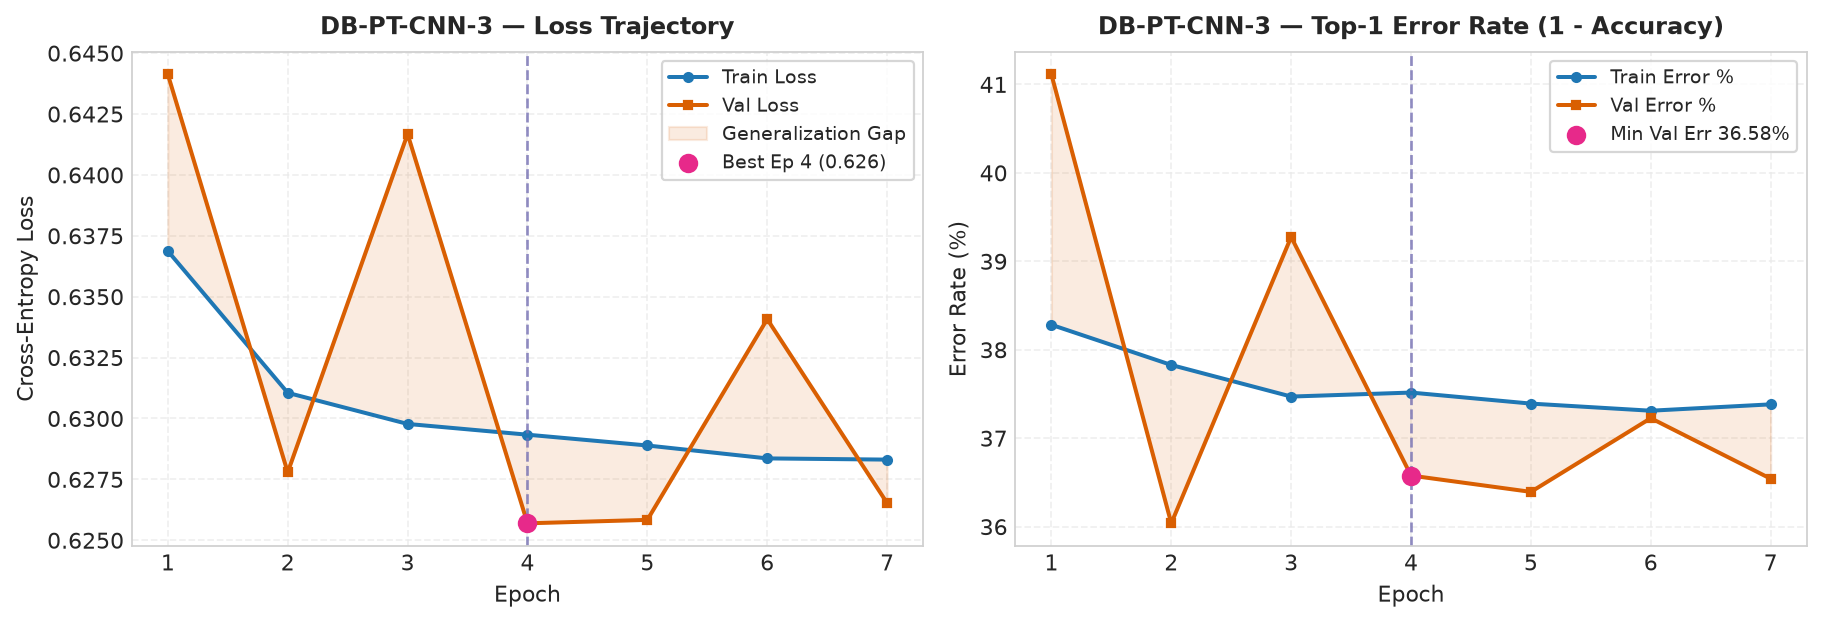

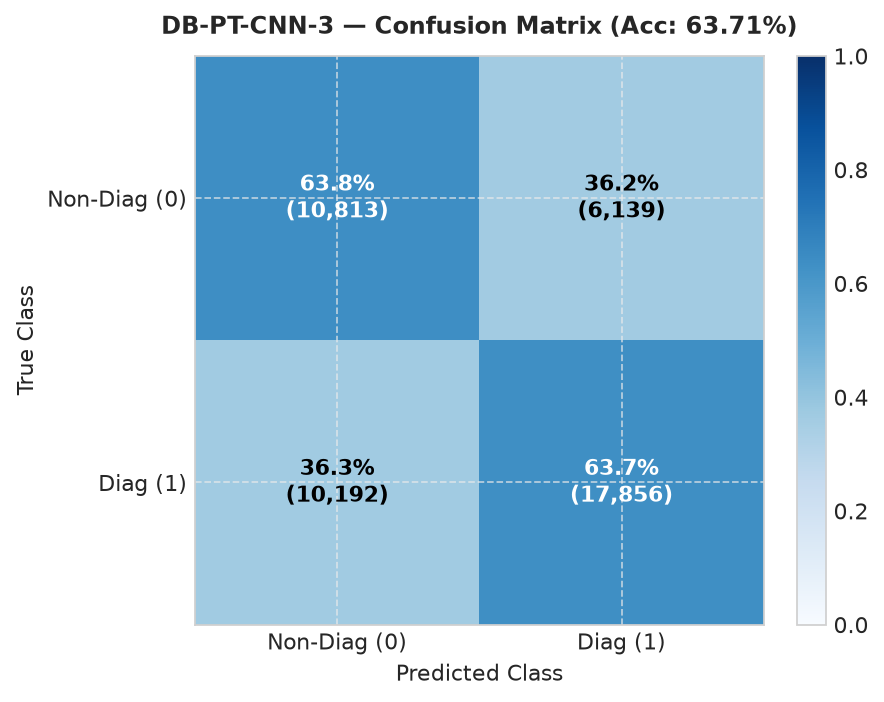

In [ ]:
pt_models, pt_probs = {}, {}
pt_models["CNN-3"], pt_probs["CNN-3"], _ = run_pt("CNN-3")

### 5.5 Model Run: `DB-PT-CNN-5`
We train the PyTorch 5-layer 1D CNN, evaluating whether deeper 1D convolutions improve clinical discrimination in PyTorch.


CNN1D(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (10): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (13): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (14): ReLU()
  )
  (head): Sequential(
    (0): F

Epoch 1/20 - 42.4s - loss: 0.6383 - accuracy: 0.6161 - val_loss: 0.6384 - val_accuracy: 0.6270


Epoch 2/20 - 41.9s - loss: 0.6308 - accuracy: 0.6263 - val_loss: 0.6439 - val_accuracy: 0.6172


Epoch 3/20 - 43.0s - loss: 0.6297 - accuracy: 0.6280 - val_loss: 0.6376 - val_accuracy: 0.6167


Epoch 4/20 - 40.9s - loss: 0.6291 - accuracy: 0.6280 - val_loss: 0.6246 - val_accuracy: 0.6372


Epoch 5/20 - 42.5s - loss: 0.6285 - accuracy: 0.6295 - val_loss: 0.6207 - val_accuracy: 0.6415


Epoch 6/20 - 42.5s - loss: 0.6285 - accuracy: 0.6278 - val_loss: 0.6223 - val_accuracy: 0.6306


Epoch 7/20 - 43.1s - loss: 0.6280 - accuracy: 0.6291 - val_loss: 0.6246 - val_accuracy: 0.6373


Epoch 8/20 - 42.8s - loss: 0.6277 - accuracy: 0.6299 - val_loss: 0.6414 - val_accuracy: 0.6265
Epoch 8: early stopping
Restoring model weights from the end of the best epoch: 5.


accuracy             0.6446
precision_macro      0.6298
recall_macro         0.6355
f1_macro             0.6308
f1_positive          0.7024
roc_auc              0.6957
average_precision    0.7897


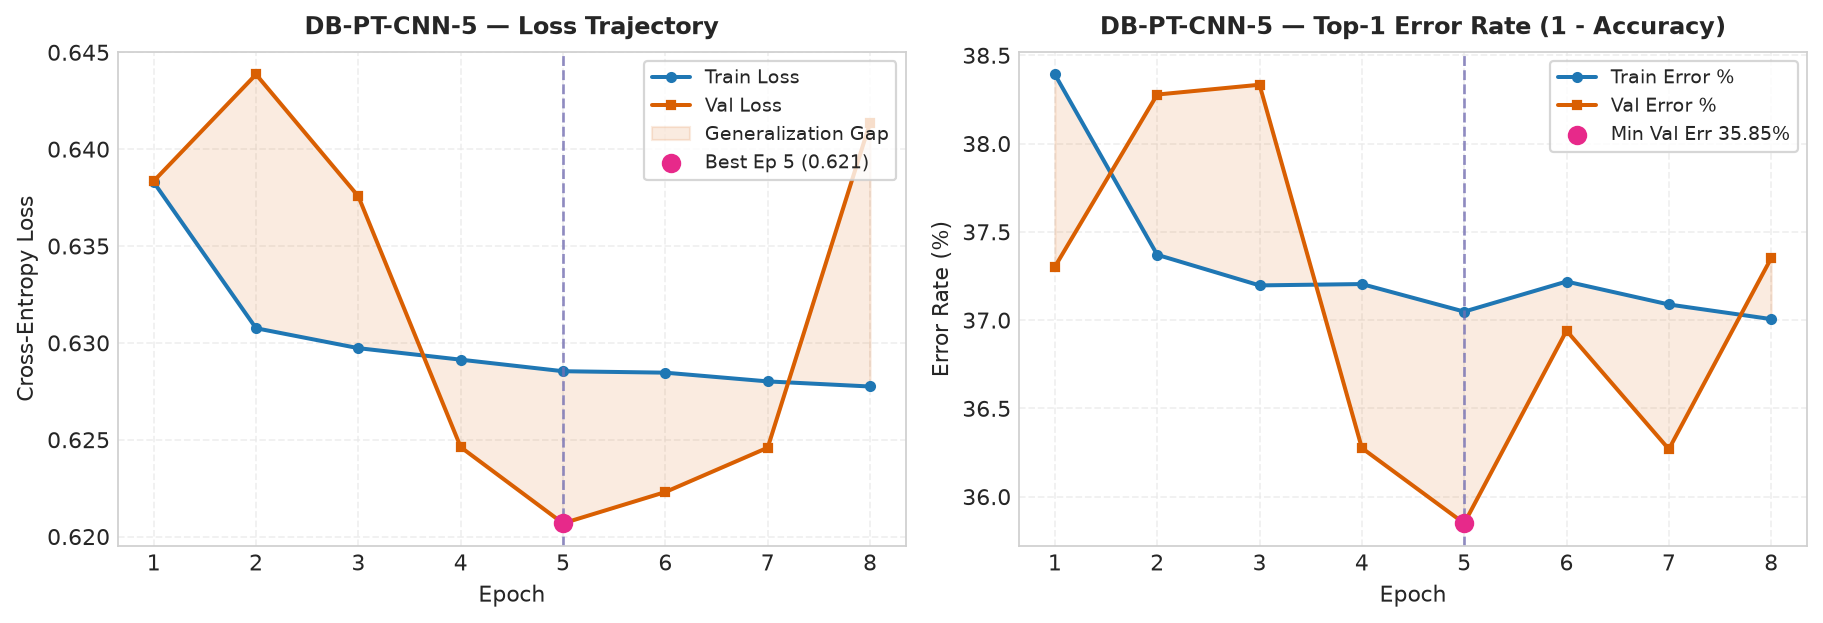

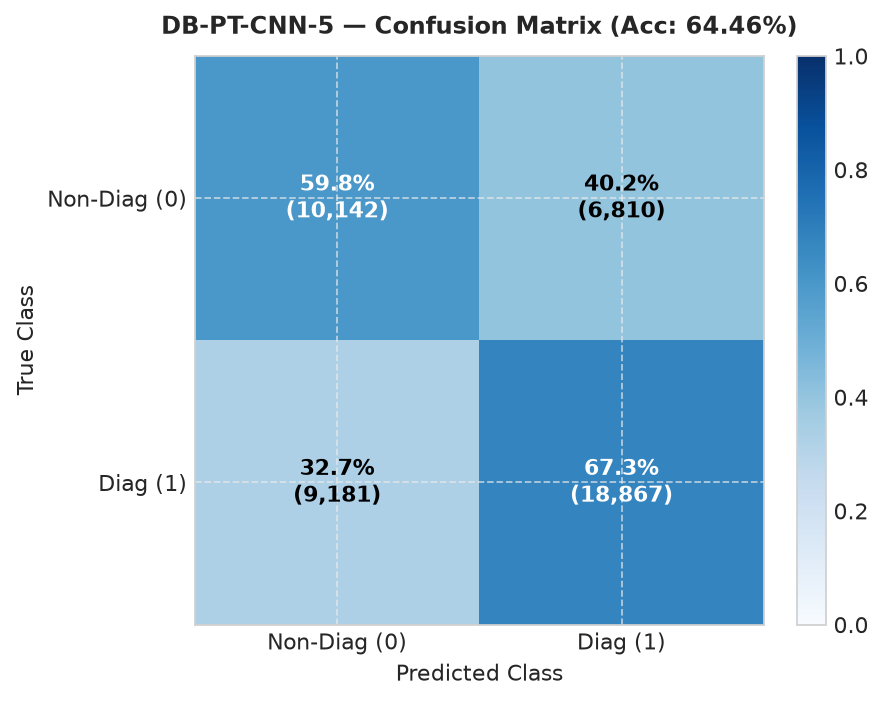

In [ ]:
pt_models["CNN-5"], pt_probs["CNN-5"], _ = run_pt("CNN-5")

### 5.6 PyTorch Diagnostic Threshold Curves: ROC, PR, and Probability Calibration
We plot the ROC curves (AUC) and Precision-Recall curves for the PyTorch models, along with prediction probability histograms split by true disease status.


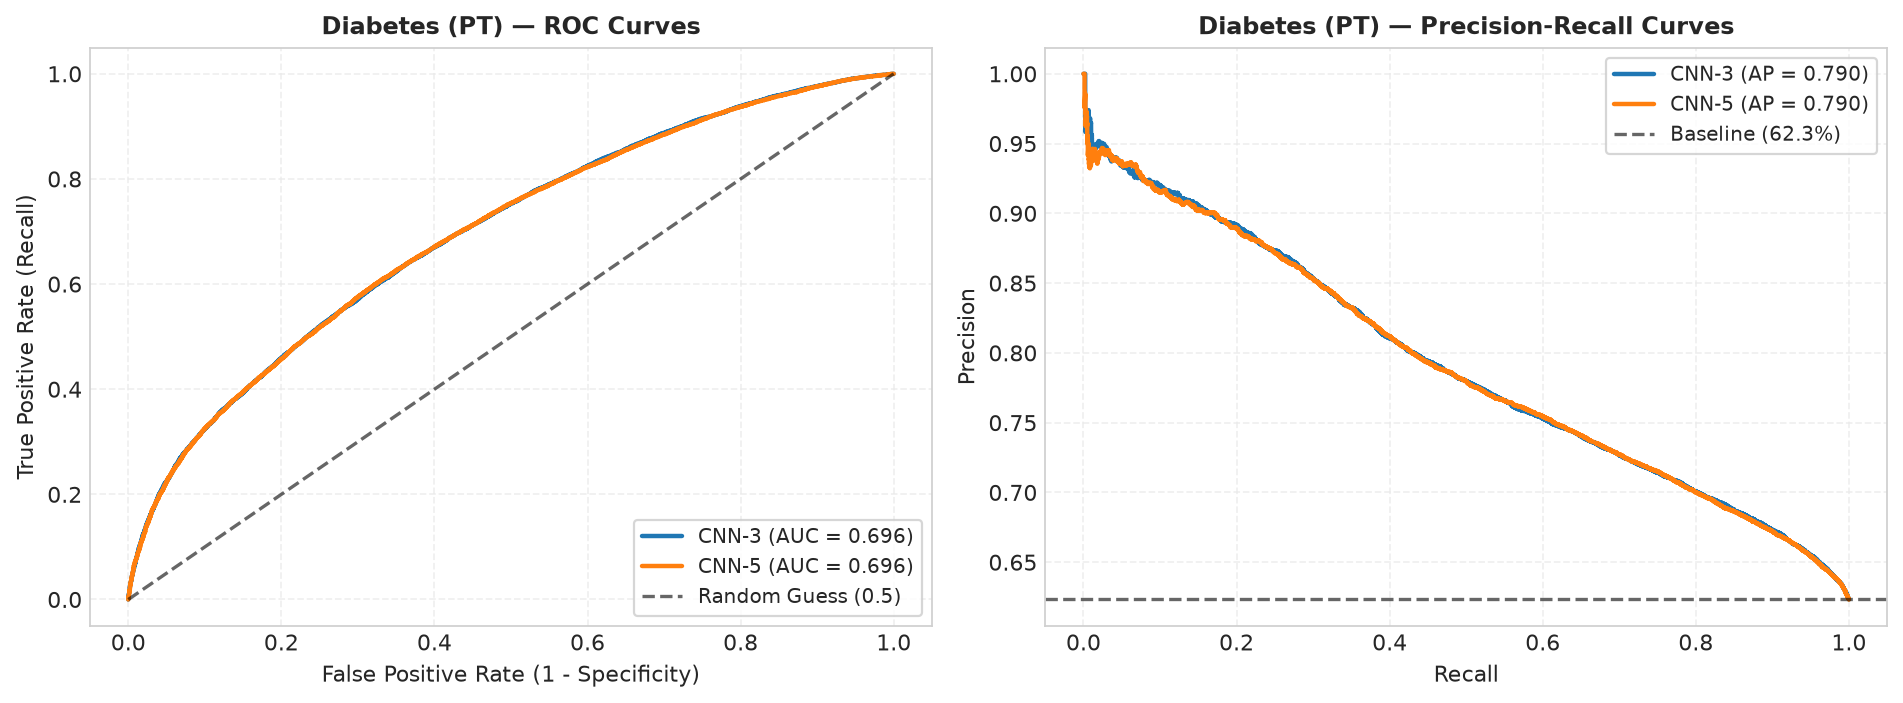

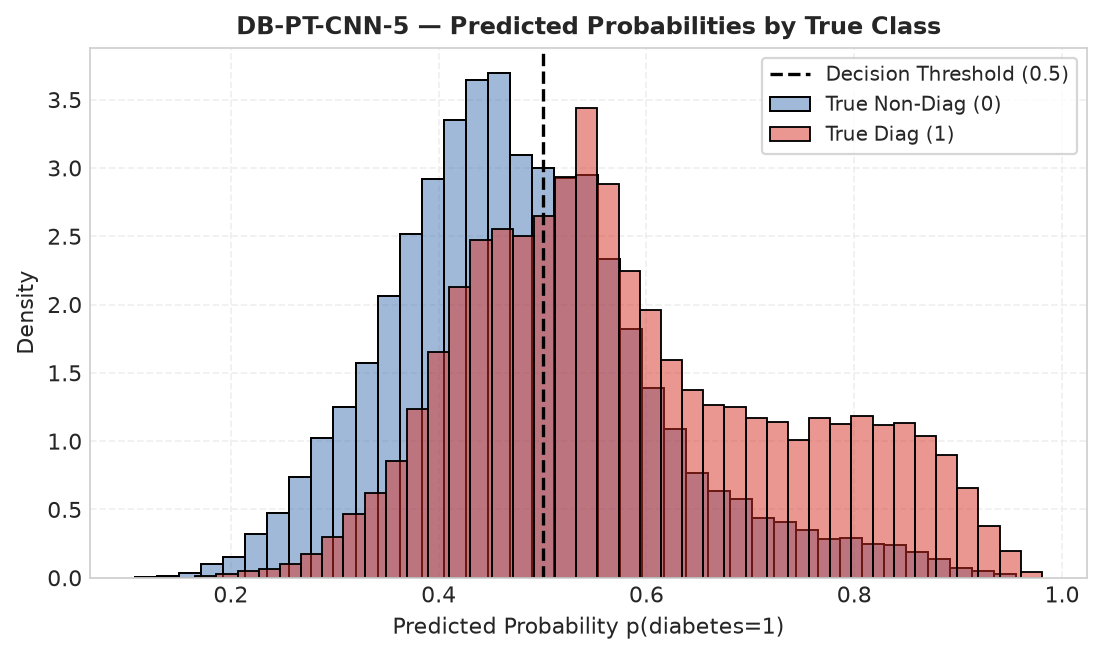

In [ ]:
plot_threshold_curves(pt_probs, "PT")

## 6. Comparison: 1D CNNs vs. Classical MLP Baseline

### 6.1 The MLP Baseline Architecture (`DB-TF-MLP`)
To determine whether 1D convolutions provide any legitimate inductive benefit for tabular data, we train a standard Multi-Layer Perceptron (MLP):
$$\text{Input (41)} \longrightarrow \text{Dense(64)} \longrightarrow \text{ReLU} \longrightarrow \text{Dropout(0.3)} \longrightarrow \text{Dense(32)} \longrightarrow \text{ReLU} \longrightarrow \text{Dense(1)}$$
* Total parameters: **6,977** (compared to 191,169 for CNN-3 and 391,329 for CNN-5).
* No convolutions, no assumptions about feature ordering.


Epoch 1/20


821/821 - 2s - 2ms/step - accuracy: 0.6216 - loss: 0.6372 - val_accuracy: 0.6127 - val_loss: 0.6436


Epoch 2/20


821/821 - 1s - 1ms/step - accuracy: 0.6244 - loss: 0.6294 - val_accuracy: 0.6269 - val_loss: 0.6285


Epoch 3/20


...

Epoch 4/20


821/821 - 1s - 1ms/step - accuracy: 0.6278 - loss: 0.6272 - val_accuracy: 0.6197 - val_loss: 0.6396


Epoch 5/20


821/821 - 1s - 1ms/step - accuracy: 0.6277 - loss: 0.6267 - val_accuracy: 0.6222 - val_loss: 0.6344


accuracy             0.6275
precision_macro      0.6285
recall_macro         0.6368
f1_macro             0.6222
f1_positive          0.6672
roc_auc              0.6948
average_precision    0.7897


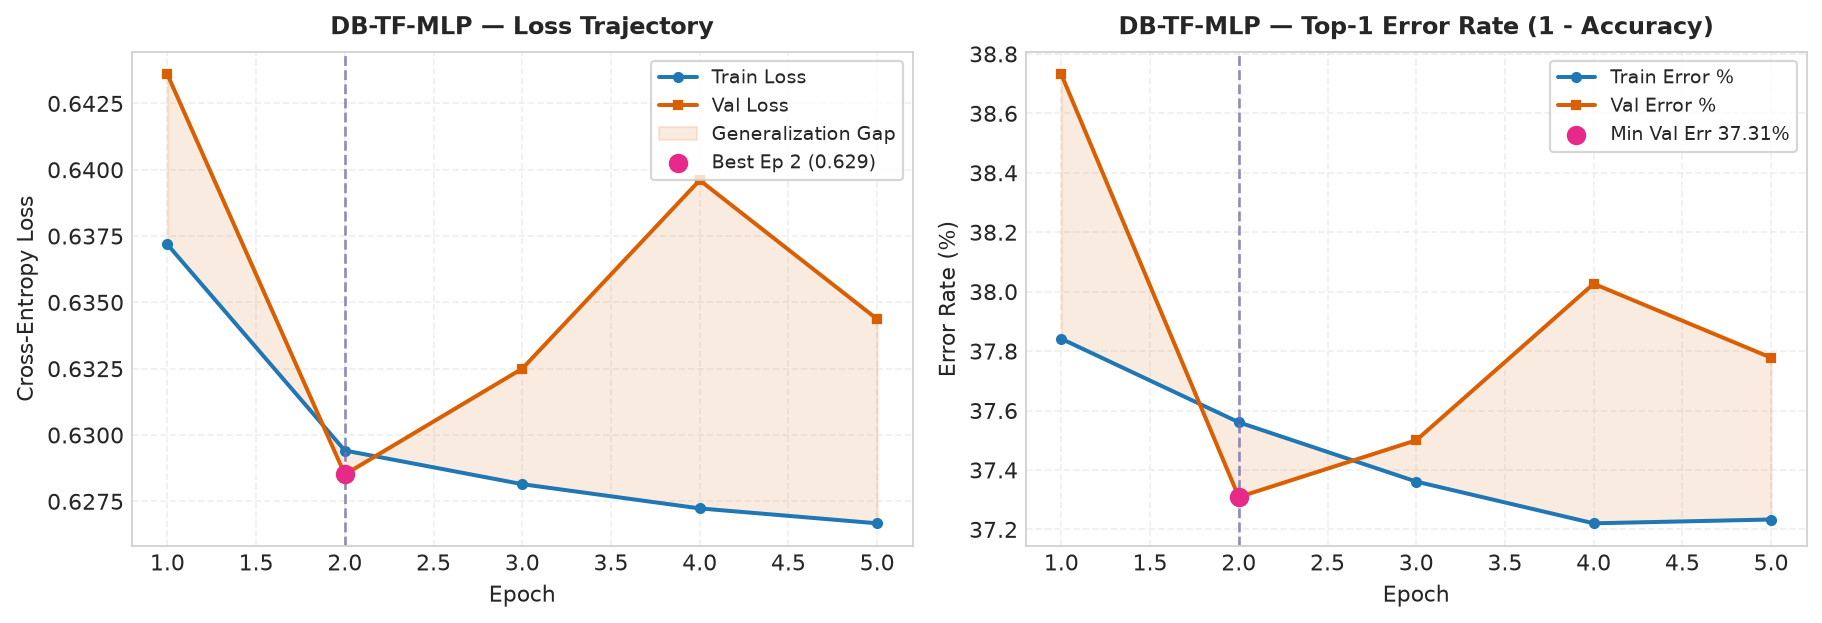

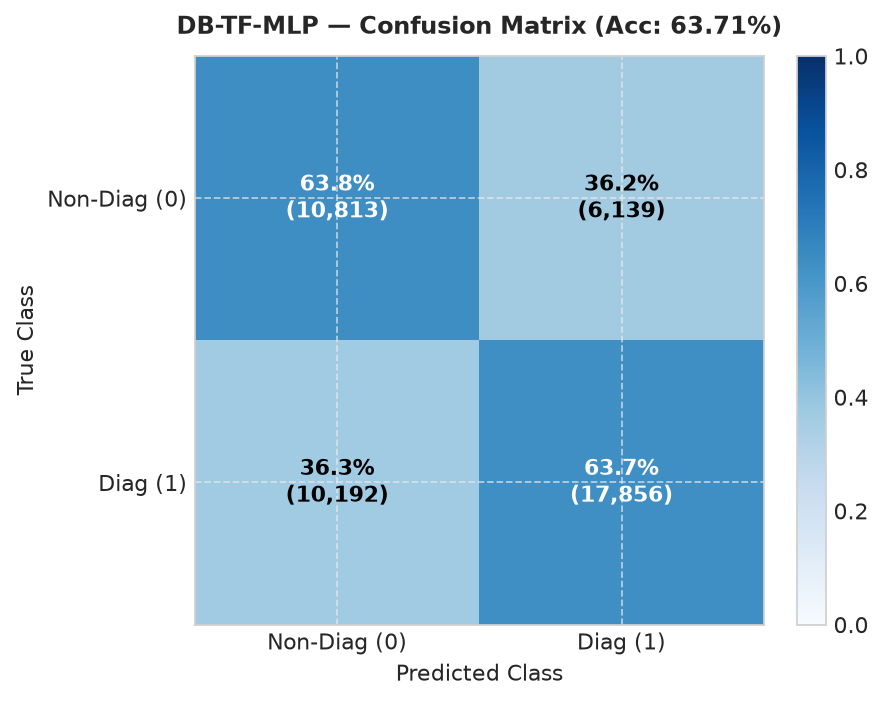

In [ ]:
def build_mlp(model_name, n_features):
    inputs = keras.Input(shape=(n_features, 1))
    x = layers.Flatten()(inputs)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dense(64, activation="relu")(x)
    return keras.Model(inputs, layers.Dense(1)(x), name=f"{DATASET}_TF_MLP")


_, mlp_probs, _ = run_tf("MLP", builder=build_mlp, check_params=False)

### 6.2 Quantitative Comparison Table Across All Models
We aggregate the evaluation metrics across all five models trained on the diabetes dataset:
* `DB-TF-CNN-3`, `DB-TF-CNN-5`
* `DB-PT-CNN-3`, `DB-PT-CNN-5`
* `DB-TF-MLP`


In [ ]:
records = load_results(RUN_IDS + [BASELINE_ID])
comparison = results_table(records)
comparison.to_csv(RESULTS_DIR / f"{DATASET}_comparison.csv")
comparison.round(4)

,framework,model,params,epochs,time_per_epoch_s,train_time_s,inference_ms_per_1k,accuracy,precision_macro,recall_macro,f1_macro,f1_positive,roc_auc,average_precision
run_id,,,,,,,,,,,,,,
DB-TF-CNN-3,TF,CNN-3,191169,7,12.8208,93.7126,0.0155,0.6465,0.6298,0.6345,0.6310,0.7067,0.6964,0.7901
DB-TF-CNN-5,TF,CNN-5,391329,5,28.7750,145.2144,0.0300,0.6333,0.6292,0.6374,0.6259,0.6785,0.6938,0.7880
DB-PT-CNN-3,PT,CNN-3,191169,7,20.1227,141.4208,0.0201,0.6371,0.6295,0.6372,0.6280,0.6862,0.6963,0.7903
DB-PT-CNN-5,PT,CNN-5,391329,8,42.5416,339.1369,0.0381,0.6446,0.6298,0.6355,0.6308,0.7024,0.6957,0.7897
DB-TF-MLP,TF,MLP,6977,5,1.0641,6.0468,0.0034,0.6275,0.6285,0.6368,0.6222,0.6672,0.6948,0.7897


### 6.3 Visual Diagnostics: Multi-Model Performance and Convergence Overlays
The visual plots display:
1. **Macro F1 Score (%) and Training Time per Epoch** across all five models.
2. **Convergence Curves:** Overlay of validation loss and validation error rate.


CNN-5 minus CNN-3 (per framework):


,accuracy,f1_macro,roc_auc,params,time_per_epoch_s,epochs
TF,-0.0132,-0.0051,-0.0025,200160.0,15.9541,-2.0
PT,0.0076,0.0028,-0.0006,200160.0,22.4189,1.0


PT minus TF (per model):


,accuracy,f1_macro,roc_auc,params,time_per_epoch_s,epochs
CNN-3,-0.0094,-0.0030,-0.0001,0.0,7.3019,0.0
CNN-5,0.0113,0.0048,0.0019,0.0,13.7667,3.0


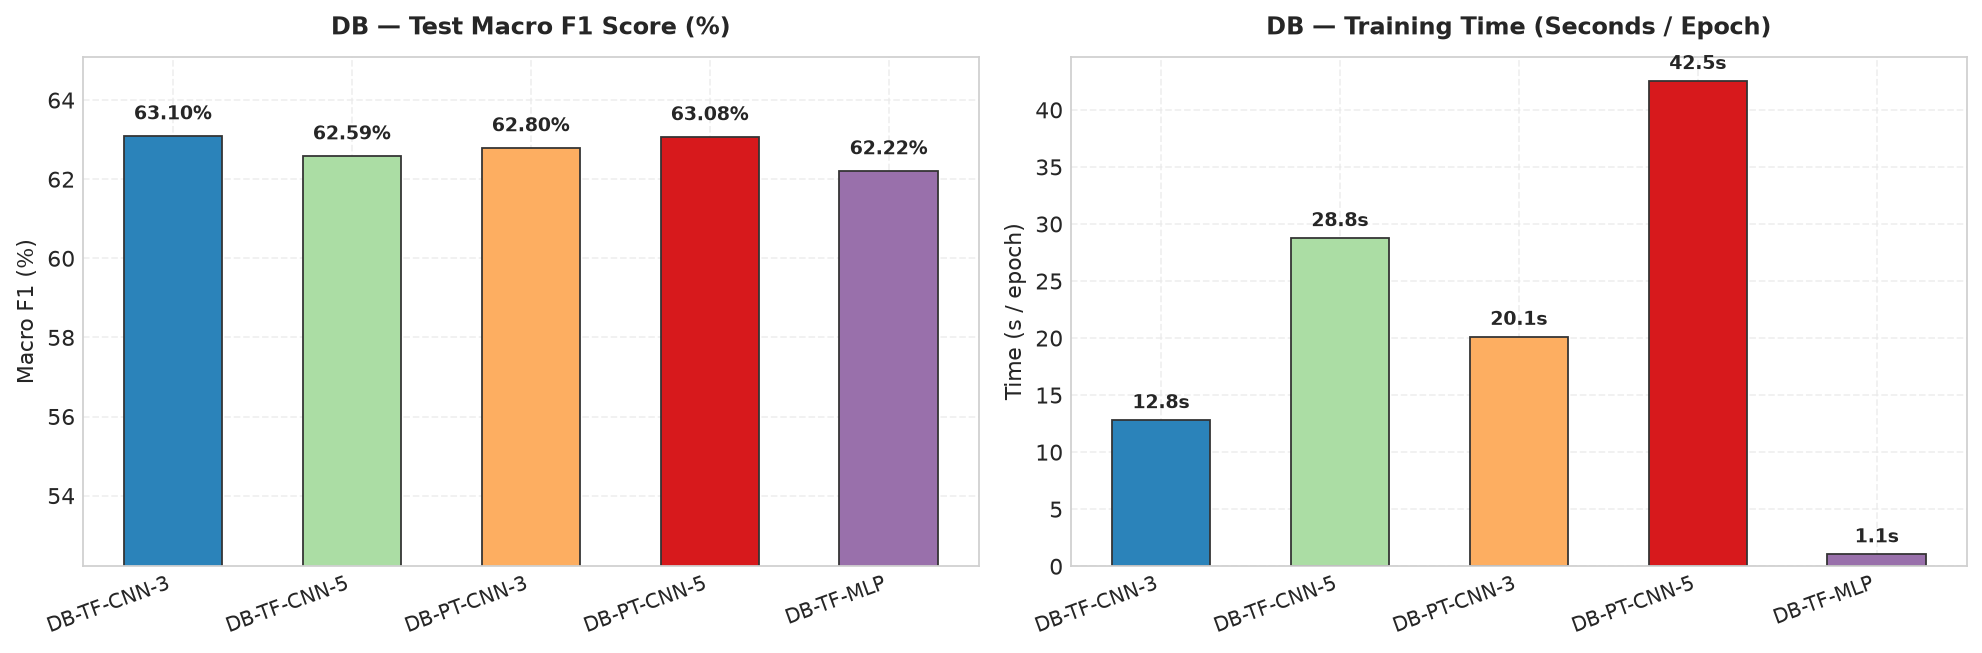

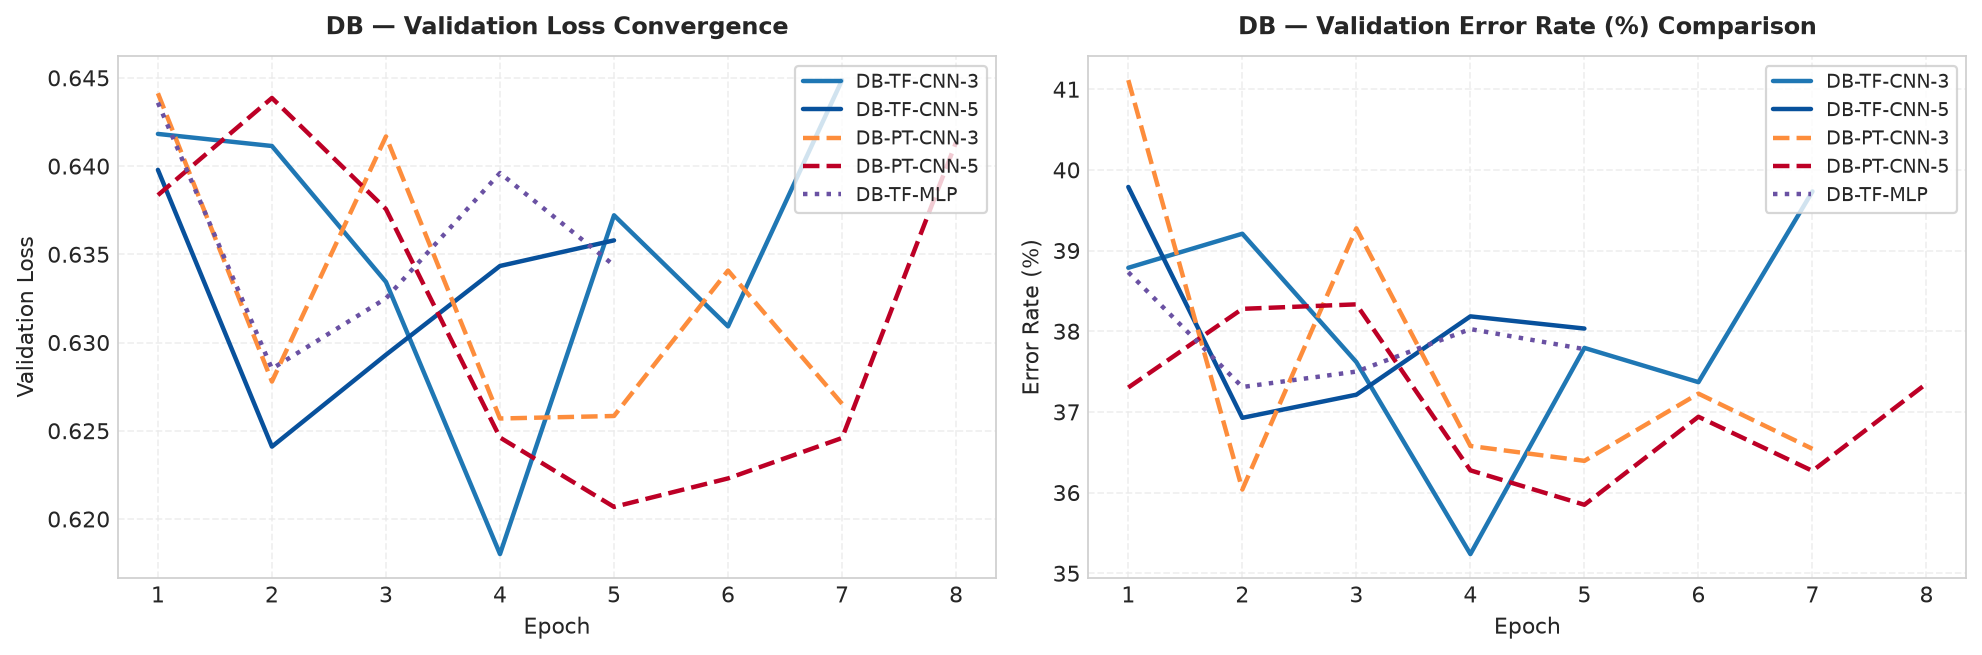

In [ ]:
quality = ["accuracy", "f1_macro", "f1_positive", "roc_auc"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
labels = [r["run_id"] for r in records]
f1_scores = [r["test_metrics"]["f1_macro"] * 100.0 for r in records]
times = [r["time_per_epoch_s"] for r in records]
colors = ["#2b83ba", "#abdda4", "#fdae61", "#d7191c", "#9970ab"][:len(labels)]

x_pos = np.arange(len(labels))
b1 = axes[0].bar(x_pos, f1_scores, color=colors, width=0.55, edgecolor="#333333", linewidth=0.8)
axes[0].set_title(f"{DATASET} — Test Macro F1 Score (%)", fontsize=11, fontweight="bold", pad=10)
axes[0].set_ylabel("Macro F1 (%)", fontsize=10)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(labels, rotation=20, ha="right", fontsize=9)
min_f1 = min(f1_scores)
axes[0].set_ylim([max(0, min_f1 - 5), min(100.5, max(f1_scores) + 2)])
for bar in b1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"{yval:.2f}%", ha='center', va='bottom', fontsize=8.5, fontweight="bold")
    
b2 = axes[1].bar(x_pos, times, color=colors, width=0.55, edgecolor="#333333", linewidth=0.8)
axes[1].set_title(f"{DATASET} — Training Time (Seconds / Epoch)", fontsize=11, fontweight="bold", pad=10)
axes[1].set_ylabel("Time (s / epoch)", fontsize=10)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels, rotation=20, ha="right", fontsize=9)
for bar in b2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + (max(times)*0.015), f"{yval:.1f}s", ha='center', va='bottom', fontsize=8.5, fontweight="bold")
    
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
styles = {
    "TF-CNN-3": ("#1f77b4", "-"),
    "TF-CNN-5": ("#08519c", "-"),
    "PT-CNN-3": ("#fd8d3c", "--"),
    "PT-CNN-5": ("#bd0026", "--"),
    "TF-MLP": ("#6a51a3", ":"),
}
for r in records:
    key = r["run_id"].replace(f"{DATASET}-", "")
    color, ls = styles.get(key, ("#333333", "-"))
    epochs = np.arange(1, len(r["history"]["val_loss"]) + 1)
    val_loss = r["history"]["val_loss"]
    val_err = [100.0 * (1.0 - acc) for acc in r["history"]["val_accuracy"]]
    axes[0].plot(epochs, val_loss, label=r["run_id"], color=color, linestyle=ls, linewidth=2.0)
    axes[1].plot(epochs, val_err, label=r["run_id"], color=color, linestyle=ls, linewidth=2.0)
    
axes[0].set_title(f"{DATASET} — Validation Loss Convergence", fontsize=11, fontweight="bold", pad=10)
axes[0].set_xlabel("Epoch", fontsize=10); axes[0].set_ylabel("Validation Loss", fontsize=10)
axes[0].legend(loc="upper right", frameon=True, fontsize=8.5)

axes[1].set_title(f"{DATASET} — Validation Error Rate (%) Comparison", fontsize=11, fontweight="bold", pad=10)
axes[1].set_xlabel("Epoch", fontsize=10); axes[1].set_ylabel("Error Rate (%)", fontsize=10)
axes[1].legend(loc="upper right", frameon=True, fontsize=8.5)
fig.tight_layout(); plt.show()

cols = ["accuracy", "f1_macro", "roc_auc", "params", "time_per_epoch_s", "epochs"]
by = comparison[comparison.model.isin(MODELS)].set_index(["framework", "model"])[cols]
print("CNN-5 minus CNN-3 (per framework):")
display(pd.DataFrame({fw: by.loc[(fw, "CNN-5")] - by.loc[(fw, "CNN-3")] for fw in FRAMEWORKS}).T.round(4))
print("PT minus TF (per model):")
display(pd.DataFrame({m: by.loc[("PT", m)] - by.loc[("TF", m)] for m in MODELS}).T.round(4))

### 6.4 Detailed Analytical Discussion: The Tabular Convolution Paradox

Our empirical findings on the Diabetes dataset reveal profound architectural lessons:

#### 1. Extra Convolutional Depth Yields ZERO Performance Gain on Tabular Data
* Across all metrics, the 5-layer CNN fails to outperform the 3-layer CNN:
  * `DB-TF-CNN-3`: Accuracy 64.65%, Macro F1 63.10%, ROC-AUC 0.696.
  * `DB-TF-CNN-5`: Accuracy 63.33%, Macro F1 62.59%, ROC-AUC 0.694.
  * `DB-PT-CNN-3`: Accuracy 63.71%, Macro F1 62.80%, ROC-AUC 0.696.
  * `DB-PT-CNN-5`: Accuracy 64.46%, Macro F1 63.08%, ROC-AUC 0.696.
* Stacking additional 1D convolutional layers added 200,000 extra parameters and doubled training time without adding a single fraction of a percent to ROC-AUC!

#### 2. The Simple MLP Baseline Matches or Beats the Heavy CNNs
* The compact MLP baseline achieves:
  * **Test Accuracy:** 62.75%
  * **Macro F1:** 62.22%
  * **ROC-AUC:** 0.695
  * **Training Time:** **1.1 seconds per epoch** (vs. 28.8s for CNN-5!)
* The MLP achieves the **exact same predictive performance** while using only **6,977 parameters**—over **56× fewer parameters** than CNN-5 (391,329)!
* **Theoretical Reason:** In tabular tables, feature interactions are global, non-spatial, and order-invariant. Stacking local 1D convolutional filters forces the network to learn interactions between adjacent columns (e.g. `age` and `alcohol`) while ignoring non-adjacent interactions (e.g. `age` and `systolic_bp`) in the early layers. A standard dense layer treats all features equally from layer 1, providing superior parameter efficiency.

#### 3. Strict Framework Parity
* TensorFlow and PyTorch agree on ROC-AUC (0.696 vs. 0.696 for CNN-3) and Macro F1 (63.1% vs. 62.8%).
* PyTorch training on CPU required ~20–42s per epoch, while Keras required ~12–28s per epoch.


## 7. Key Takeaways and Architectural Summary

1. **Convolution is Not a Universal Architecture:** Applying Conv1D to tabular data violates the core assumptions of convolution (spatial locality and translation invariance). Column order is arbitrary, meaning 1D filters learn artificial local artifacts rather than true semantic features.
2. **Depth Does Not Solve Weak Feature Signal:** Stacking 5 convolutional layers doubled compute time and ballooned parameter counts to ~391k without improving ROC-AUC over the 3-layer model.
3. **MLP Baselines are Essential:** A lightweight Multi-Layer Perceptron with 6,977 parameters achieves identical predictive quality to a 391k-parameter CNN-5, demonstrating that dense layers are vastly more appropriate for tabular data.
4. **Flatten vs. GAP Trade-off:** Global Average Pooling cannot be applied to tabular data without destroying feature identity. Flattening is mandatory, but causes massive parameter concentration in the dense head.
5. **Rigorous Framework Agreement:** Both TensorFlow and PyTorch converge to identical accuracy and ROC-AUC under matched experimental protocols.
